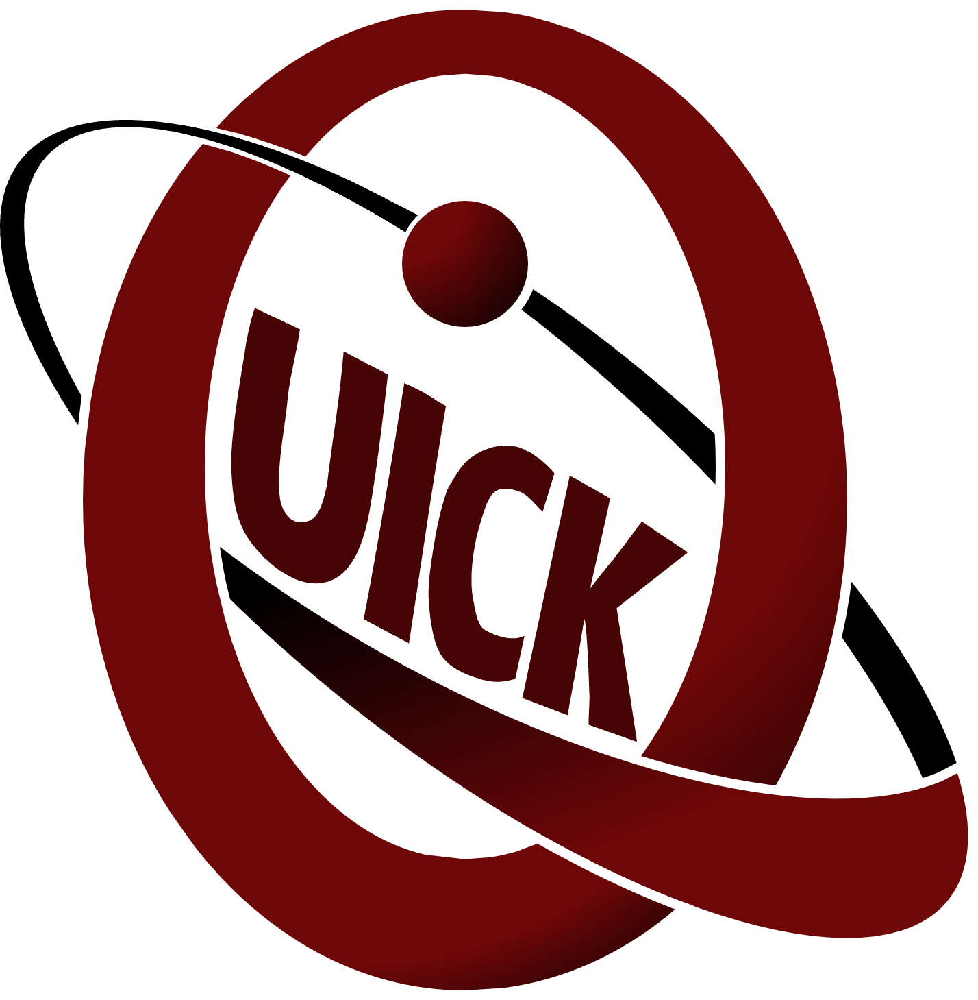

# Q-LINK — 세 실험실을 연결하라

**Qiskit Fall Fest · QUICK · 고려대학교 | 참가자용**

**Colab ver3 · TODO 작성 후 모두 실행 · 채점·제출 파일 저장**


Alice, Bob, Charlie의 세 실험실이 양자 네트워크 실험을 준비합니다.
여러분은 담당 엔지니어로서 **측정과 얽힘 자원을 점검하고, Alice의 양자 상태를 Bob에게 전송한 뒤, 세 실험실의 협력 시험을 수행합니다.**
개통 보고서에는 상태를 구별한 근거, 전송 복구 결과, 고전 전략과의 성능 차이를 작성하세요.

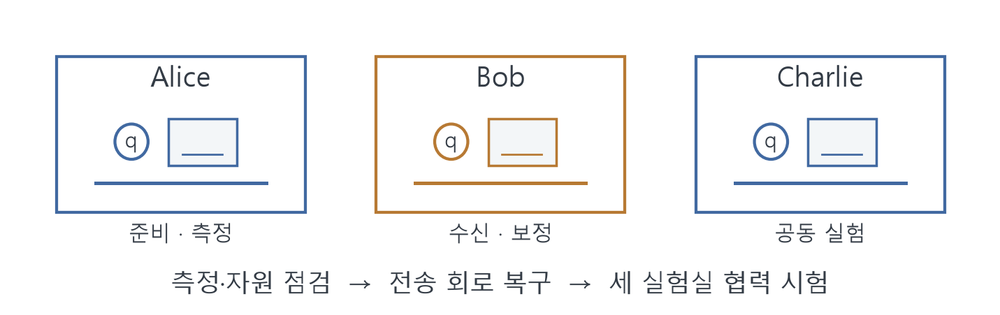

[1. 측정·얽힘](#part1) · [2. 텔레포테이션](#part2) · [3. GHZ–Mermin 게임](#part3) · [선택 심화](#optional) · [개통 보고서·제출](#finish)


# 실행 조건과 제출 방식

**이 노트북을 Colab에서 열고 준비 A 셀만 실행**하시면 됩니다. 

준비 A가 [공식 GitHub Release v2.0.3](https://github.com/equivoque-jk/qff-2026-grader/releases/tag/v2.0.3)에서 채점 패키지와 필요한 실험 도구를 자동으로 받아 설치합니다. 최초 설치에는 인터넷 연결이 필요하며, 필요한 패키지가 지정된 버전으로 이미 설치되어 있으면 설치를 건너뜁니다. 일반 Jupyter에서도 같은 준비 A 셀을 실행하시면 됩니다. 설치가 실패하면 준비 A의 로그에서 GitHub 접속과 패키지 설치 오류를 확인한 뒤 다시 실행하세요.

설치 후 Colab에서 재시작 안내가 나오면 **런타임 → 세션 다시 시작**을 선택한 뒤 **준비 A 셀만 다시 실행**하세요. 준비 완료가 표시되면 준비 B·C·D와 해당 파트의 제공 도구·문제 셀을 필요한 순서대로 실행하며 풀이를 진행하시면 됩니다. 세션을 다시 시작하면 이전 변수와 함수 정의도 사라지므로, 화면에 예전 출력이 남아 있어도 필요한 셀은 다시 실행하셔야 합니다.

**23개 함수의 `TODO BEGIN`과 `TODO END` 사이 영역에 코드를 작성하시면 됩니다.** 영역 안의 `raise NotImplementedError(...)`를 지우고 구현하세요. 함수 선언, 제공 초기화, 마지막 `return`, 실행·채점 셀은 그대로 두시면 됩니다. 각 문항에서 지정한 연산과 반환 조건을 지키는 범위에서 회로와 수치 계산을 구현하세요. 특히 1-1~1-3은 최종 상태뿐 아니라 지정된 게이트의 종류·횟수·순서도 검사합니다. 이 세 문항에서는 결과가 같아지는 추가 게이트도 넣지 마세요. 회로 구분용 `barrier`는 이 게이트 목록 검사에서 제외합니다.

**전체 답안을 채점하고 제출 ZIP을 만들 때** **런타임 → 모두 실행**을 선택하세요. 실험, 최종 채점, 제출 파일 저장이 순서대로 진행됩니다. 초기 환경 준비와 개별 문제 풀이 중에는 필요한 셀만 실행하셔도 괜찮습니다. 선택 문제를 작성하지 않았다면 TODO를 그대로 두세요. 마지막 셀이 선택 문항의 작성 여부를 판단하므로 목록·파일명·채점 명령을 따로 입력하지 않으셔도 괜찮습니다. Colab에서는 제출 ZIP 다운로드를 요청합니다. 다운로드가 실패하거나 일반 Jupyter를 사용하는 경우에는 출력창에 표시된 경로·링크에서 파일을 받으세요.

- **Colab CPU · 이상적 Aer · 표본 실험은 측정 설정당 4096 shots.** 준비 셀과 각 파트의 제공 도구를 순서대로 실행하세요. Colab의 IPython 버전은 설치 중 그대로 유지합니다.
- 제출 회로에는 측정·reset·추가 qubit·postselection을 넣지 않습니다. 제공 코드가 상태 준비·측정·검증을 연결합니다.
- 기본 허용 게이트는 H/X/Z/CX입니다. 국소 측정 변환은 H/X/Z를 사용하며, **3-2의 `local_basis()`에만 S/S†를 추가로 허용**합니다. `build_ghz3()`의 허용 게이트는 H/X/Z/CX입니다.
- Bob 보정은 H/X/Z와 `if_test`를 사용합니다. `if_test`의 조건은 **반환 회로의 고전 비트 하나를 0 또는 1과 비교하는 형태**여야 합니다. 여러 비트의 조건을 함께 확인하려면 단일 비트 조건문을 중첩하세요. 고전 레지스터 전체의 값 비교나 고전 논리식을 조건으로 사용하는 방식은 허용하지 않습니다.
- 상태·결과 문자열에서 q0·c0가 가장 오른쪽입니다. 각 측정 기저에서 매 시행(shot)마다 상태를 새로 준비하며, 전역 위상 차이는 무시합니다. 함수는 자신의 인자와 공개 문제 정의만 사용합니다.

**채점 대상은 함수가 반환한 회로와 계산 결과입니다.** 문제별 실행 셀은 상태 준비·측정·관찰용 계산을 수행하고, 마지막 채점 셀은 답안 함수의 반환값을 수집하여 검사합니다. 4096-shot 출력은 관찰·비교용입니다. 수치 답안 함수에는 이상적 회로의 정확한 확률·밀도행렬에서 계산한 값을 반환하세요. ⟨Z⟩의 실험 추정값은 `(N₀−N₁)/N`입니다.

실험 메모는 채점 내용에 포함되지 않습니다.

기본 문항은 **총 100점**, 선택 심화는 **추가 20점**입니다.


In [ ]:
#@title 준비 A — 채점 패키지와 실험 환경 준비 (자동)
# GitHub Release의 지정된 버전을 설치합니다. 이미 준비된 환경에서는 재설치하지 않습니다.
import importlib as _qff_importlib
import importlib.metadata as _qff_metadata
import subprocess as _qff_subprocess
import sys as _qff_sys

print("[준비 A 1/4] Python·설치 패키지를 확인합니다.", flush=True)
if not ((3, 10) <= _qff_sys.version_info[:2] < (3, 14)):
    raise RuntimeError("Python 3.10–3.13 환경이 필요합니다. Colab의 지원 런타임에서 다시 실행하세요.")
try:
    from google.colab import files as _qff_colab_files
except ImportError:
    _qff_is_colab = False
else:
    _qff_is_colab = True

_qff_required = {
    "qff-local-grader": "2.0.3", "qiskit": "2.3.1", "numpy": "2.2.6",
    "psutil": "7.2.2", "qiskit-aer": "0.17.2", "matplotlib": "3.10.8",
    "pylatexenc": "2.10", "ipython": None, "nbformat": None,
}
_qff_colab_ipython = None
if _qff_is_colab:
    # Colab's shell depends on its own IPython version. Preserve the live kernel version.
    _qff_colab_ipython = getattr(_qff_sys.modules.get("IPython"), "__version__", None)
    if _qff_colab_ipython is None:
        _qff_colab_ipython = _qff_metadata.version("ipython")
    _qff_required["ipython"] = _qff_colab_ipython
    print("Colab 커널의 IPython " + _qff_colab_ipython + " 버전을 유지합니다.", flush=True)

_qff_install_needed = False
_qff_before_versions = {}
for _qff_distribution, _qff_expected in _qff_required.items():
    try:
        _qff_actual = _qff_metadata.version(_qff_distribution)
    except _qff_metadata.PackageNotFoundError:
        _qff_before_versions[_qff_distribution] = None
        _qff_install_needed = True
    else:
        _qff_before_versions[_qff_distribution] = _qff_actual
        if _qff_expected is not None and _qff_actual != _qff_expected:
            _qff_install_needed = True

if _qff_install_needed:
    print("[준비 A 2/4] GitHub Release v2.0.3에서 설치할 패키지를 확인합니다.", flush=True)
    _qff_package_url = "https://github.com/equivoque-jk/qff-2026-grader/releases/download/v2.0.3/qff_local_grader-2.0.3-py3-none-any.whl#sha256=0f17e928e94344216cf9cf8f8df9183dd324cb94f605b5c0c915b777dc149a1a"
    _qff_modules = {
        "qff-local-grader": "qff_grader", "qiskit": "qiskit", "numpy": "numpy",
        "psutil": "psutil", "qiskit-aer": "qiskit_aer", "matplotlib": "matplotlib",
        "pylatexenc": "pylatexenc", "ipython": "IPython", "nbformat": "nbformat",
    }
    _qff_loaded_before_install = {
        _qff_dist: getattr(_qff_sys.modules[_qff_module], "__version__", None)
        for _qff_dist, _qff_module in _qff_modules.items() if _qff_module in _qff_sys.modules
    }
    _qff_install_command = [
        _qff_sys.executable, "-m", "pip", "install", "--progress-bar", "off",
        "qff-local-grader[notebook] @ " + _qff_package_url,
    ]
    if _qff_colab_ipython:
        _qff_install_command.append("ipython==" + _qff_colab_ipython)
    print("[준비 A 3/4] 패키지 설치를 시작합니다. 아래 로그가 진행 상황입니다. (최대 10분)", flush=True)
    import queue as _qff_queue
    import threading as _qff_threading
    import time as _qff_time
    _qff_process = _qff_subprocess.Popen(
        _qff_install_command, stdout=_qff_subprocess.PIPE, stderr=_qff_subprocess.STDOUT,
        text=True, bufsize=1,
    )
    _qff_lines = _qff_queue.Queue()
    def _qff_read_install_log():
        try:
            for _qff_line in _qff_process.stdout:
                _qff_lines.put(_qff_line)
        finally:
            _qff_lines.put(None)
    _qff_reader = _qff_threading.Thread(target=_qff_read_install_log, daemon=True)
    _qff_reader.start()
    _qff_deadline = _qff_time.monotonic() + 600
    _qff_last_notice = _qff_time.monotonic()
    while True:
        if _qff_time.monotonic() >= _qff_deadline:
            _qff_process.kill()
            _qff_process.wait(timeout=10)
            raise RuntimeError("설치가 10분 제한을 초과하여 중단했습니다. 네트워크 상태를 확인한 뒤 준비 A를 다시 실행하세요.")
        try:
            _qff_line = _qff_lines.get(timeout=1)
        except _qff_queue.Empty:
            if _qff_time.monotonic() - _qff_last_notice >= 30:
                print("설치 프로세스가 실행 중입니다. 다음 설치 로그를 기다립니다.", flush=True)
                _qff_last_notice = _qff_time.monotonic()
            continue
        if _qff_line is None:
            break
        print(_qff_line, end="", flush=True)
    try:
        _qff_returncode = _qff_process.wait(timeout=max(1, _qff_deadline - _qff_time.monotonic()))
    except _qff_subprocess.TimeoutExpired:
        _qff_process.kill()
        _qff_process.wait(timeout=10)
        raise RuntimeError("설치가 10분 제한을 초과했습니다. 준비 A의 설치 로그를 확인하세요.") from None
    if _qff_returncode != 0:
        raise RuntimeError("설치가 완료되지 않았습니다. 위 pip 오류를 확인하고 준비 A를 다시 실행하세요.")
    print("패키지 설치가 완료됐습니다.", flush=True)
    _qff_importlib.invalidate_caches()
    _qff_changed_loaded = [
        _qff_dist for _qff_dist, _qff_loaded_version in _qff_loaded_before_install.items()
        if _qff_before_versions[_qff_dist] != _qff_metadata.version(_qff_dist)
        and _qff_loaded_version != _qff_metadata.version(_qff_dist)
    ]
    if _qff_changed_loaded:
        print("설치 성공. 메모리에 남은 이전 버전: " + ", ".join(_qff_changed_loaded), flush=True)
        raise RuntimeError(
            "런타임 관련 오류입니다. Colab 메뉴 '런타임 → 세션 다시 시작'을 선택한 뒤 "
            "준비 A 셀만 다시 실행하세요. 일반 Jupyter에서는 커널을 다시 시작한 뒤 준비 A를 실행하세요. "
            "준비 완료 후 준비 B·C·D와 필요한 문제 셀을 순서대로 실행하세요. "
            "'모두 실행'은 전체 답안을 채점하고 제출 ZIP을 만들 때 선택합니다."
        )
else:
    print("[준비 A 2–3/4] 필요한 버전이 설치되어 있습니다. 설치를 건너뜁니다.", flush=True)

print("[준비 A 4/4] 실제 로드된 버전과 실험 환경을 확인합니다.", flush=True)
import qff_grader as _qff_package
if _qff_package.__version__ != "2.0.3":
    raise RuntimeError("이전 채점 패키지가 메모리에 남아 있습니다. '런타임 → 세션 다시 시작' 후 준비 A 셀만 다시 실행하세요.")
from qff_grader import check_runtime, reset_submission_state, finalize_submission
_qff_runtime = check_runtime(require_notebook=True)
reset_submission_state(globals())
print("QFF 2.0.3 준비 완료 — 준비 B·C·D와 필요한 문제 셀을 순서대로 실행하며 TODO를 작성하세요.", flush=True)
print("전체 답안을 채점하고 제출 ZIP을 만들 때 '런타임 → 모두 실행'을 선택하세요.", flush=True)


In [ ]:
#@title 준비 B — 설치 버전 확인
import sys, qiskit, qiskit_aer, numpy, matplotlib
print("Python", sys.version.split()[0])
print("Qiskit", qiskit.__version__, "Aer", qiskit_aer.__version__)
print("NumPy", numpy.__version__, "Matplotlib", matplotlib.__version__)
assert qiskit.__version__ == "2.3.1" and qiskit_aer.__version__ == "0.17.2"

In [ ]:
#@title 준비 C — 공용 실행 도구
"""Provided helpers, embedded into each notebook so Colab needs no local files."""
import itertools
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.circuit import Clbit
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, state_fidelity
from qiskit_aer import AerSimulator
from IPython.display import display

SHOTS = 4096
SEED = 20260909
BACKEND = AerSimulator(max_parallel_threads=2)


def compile_for_aer(qc, seed=SEED):
    # Lower state preparation to portable gates, avoiding backend-specific
    # multiplexer instructions. This also works inside classical if blocks.
    return transpile(qc, basis_gates=["u", "cx"], optimization_level=0,
                     seed_transpiler=seed, num_processes=1)

"""Circuit contract for educational checks; not a Python security sandbox."""
from qiskit.circuit import Barrier, Clbit, IfElseOp
from qiskit.circuit.library import HGate, XGate, ZGate, CXGate, SGate, SdgGate


def validate_fragment(qc, nq, nc=0, allowed=("h", "x", "z", "cx"), conditional=False):
    """Check standard gate identity and arity, including conditional bodies."""
    if not isinstance(qc, QuantumCircuit) or (qc.num_qubits, qc.num_clbits) != (nq, nc):
        raise ValueError(f"Expected QuantumCircuit({nq}, {nc})")
    if qc.parameters:
        raise ValueError("Bind all circuit parameters before submission")
    standard = {"h": HGate, "x": XGate, "z": ZGate, "cx": CXGate,
                "s": SGate, "sdg": SdgGate}
    for item in qc.data:
        op = item.operation
        if type(op) is Barrier:
            continue
        if type(op) is IfElseOp and conditional:
            condition = op.condition
            if not isinstance(condition, tuple) or len(condition) != 2:
                raise ValueError("Use a single local classical bit in if_test")
            bit, value = condition
            if not isinstance(bit, Clbit) or value not in (0, 1) or bit not in qc.clbits:
                raise ValueError("Use a single local classical bit in if_test")
            for block in op.blocks:
                validate_fragment(block, block.num_qubits, block.num_clbits, allowed, True)
            continue
        gate_class = standard.get(op.name)
        if op.name not in allowed or gate_class is None:
            raise ValueError(f"Operation not allowed here: {op.name}")
        canonical = gate_class()
        if (type(op) not in (gate_class, type(canonical)) or
                op.num_qubits != canonical.num_qubits or op.num_clbits or op.params or
                (op.name == "cx" and op.ctrl_state != canonical.ctrl_state)):
            raise ValueError(f"Use the standard Qiskit gate for {op.name}")
    return qc


def bit_at(key, index):
    """Global classical-bit index; independent of printed register separators."""
    return int(key.replace(" ", "")[-1-index])

_qff_experiment_errors = []


def _qff_record_experiment_error(label, exc):
    _qff_experiment_errors.append({"experiment": label, "type": type(exc).__name__, "message": str(exc)})
    print(f"실험 점검 — {label}: {type(exc).__name__}: {exc}")
    print("이 실험의 출력은 건너뜁니다. 마지막 자동 채점에서 문항별 결과를 확인하세요.")


def run_if_ready(action):
    """Keep ordinary unfinished/incorrect experiment output from blocking grading."""
    try:
        return action()
    except NotImplementedError as exc:
        print(f"미완성 — 해당 TODO를 구현한 뒤 다시 실행하세요: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(getattr(action, "__name__", "실험"), exc)


from contextlib import contextmanager as _qff_contextmanager


@_qff_contextmanager
def _qff_experiment(label):
    """Preserve module-level experiment variables while reporting ordinary errors."""
    try:
        yield
    except NotImplementedError as exc:
        print(f"미완성 — 해당 TODO를 구현한 뒤 다시 실행하세요: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(label, exc)

def show_game(report):
    print("input       correlator    win rate")
    for row in report["rows"]:
        xyz = "".join(map(str, row["input"]))
        print(f"{xyz:>5s}       {row['correlator']: .6f}    {row['win_rate']:.6f}")
    print(f"average win={report['p_win']:.6f}, M={report['M']:.6f}")

def show_fidelity(report):
    print(f"F_hat={report['fidelity']:.6f}")
    print("Alice bits     shots    branch F_hat")
    for bits, row in report["branches"].items():
        print(f"{bits:>10s}     {row['shots']:5d}    {row['fidelity']:.6f}")


In [ ]:
#@title 준비 D — 측정·그림 도구
"""Provided measurement helpers for the integrated QFF notebook."""
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp

COLORS = {"A": "#4169A1", "B": "#B77933", "reference": "#333B45"}
plt.rcParams.update({"figure.figsize": (9, 3.6), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "semibold", "figure.dpi": 120})


def initial_one_qubit(label):
    qc = QuantumCircuit(1)
    if label == "1":
        qc.x(0)
    elif label == "+":
        qc.h(0)
    elif label == "-":
        qc.x(0)
        qc.h(0)
    elif label != "0":
        raise ValueError("Use one of: 0, 1, +, -")
    return qc


def measure_subset(preparation, qubits, readout=None, shots=SHOTS, seed=SEED):
    """Each call prepares a fresh state, changes basis, then measures only listed qubits."""
    if preparation.num_clbits or shots < 1 or len(set(qubits)) != len(qubits):
        raise ValueError("Use an unmeasured preparation and distinct measured qubits")
    qc = preparation.copy()
    if readout is not None:
        validate_fragment(readout, len(qubits), allowed=("h", "x", "z", "s", "sdg"))
        qc.compose(readout, list(qubits), inplace=True)
    bits = ClassicalRegister(len(qubits), "readout")
    qc.add_register(bits)
    qc.measure(list(qubits), bits)
    counts = BACKEND.run(compile_for_aer(qc, seed), shots=shots,
                         seed_simulator=seed).result().get_counts()
    return counts


def expectation_from_counts(counts):
    total = sum(counts.values())
    if total <= 0:
        raise ValueError("Counts must contain at least one shot")
    return sum((-1)**key.replace(" ", "").count("1") * n for key, n in counts.items()) / total


def inspect_one(builder):
    qc = validate_fragment(builder(), 1)
    counts = measure_subset(qc, [0])
    display(qc.draw("mpl"))
    print("counts:", counts)
    print(f"<Z> estimate = {expectation_from_counts(counts):+.6f}")
    return counts


def inspect_four_states(builder, readout=None, draw=False):
    rows = []
    for i, label in enumerate(("0", "1", "+", "-")):
        qc = validate_fragment(builder(label), 1)
        counts = measure_subset(qc, [0], readout, seed=SEED+i)
        ev = expectation_from_counts(counts)
        rows.append((label, ev))
        if draw:
            print("Initial state:", label)
            display(qc.draw("mpl"))
    print("initial      expectation estimate")
    for label, ev in rows:
        print(f"{label:>7s}      {ev:+.6f}")
    return rows


BELL_TARGETS = {
    "Phi+": Statevector(np.array([1, 0, 0, 1])/np.sqrt(2)),
    "Phi-": Statevector(np.array([1, 0, 0, -1])/np.sqrt(2)),
    "Psi+": Statevector(np.array([0, 1, 1, 0])/np.sqrt(2)),
    "Psi-": Statevector(np.array([0, 1, -1, 0])/np.sqrt(2)),
}


def bell_experiment(transform, target):
    qc = QuantumCircuit(2)
    qc.x(0)  # Referee fixes |q1 q0> = |01>; participant cannot remove this prefix.
    qc.barrier(label="given input 01")
    qc.compose(validate_fragment(transform(target), 2), inplace=True)
    return qc


def inspect_bells(transform):
    print("target      preparation fidelity")
    for label, target in BELL_TARGETS.items():
        qc = bell_experiment(transform, label)
        print(f"{label:>6s}      {state_fidelity(Statevector(qc), target):.6f}")
        display(qc.draw("mpl"))


def plot_readout_comparison(counts_a, counts_b, title, parity=False):
    def probabilities(counts):
        n = sum(counts.values())
        if parity:
            return [sum(v for k, v in counts.items() if k.count("1") % 2 == p)/n for p in (0, 1)]
        width = len(next(iter(counts)))
        return [counts.get(f"{i:0{width}b}", 0)/n for i in range(2**width)]
    a, b = probabilities(counts_a), probabilities(counts_b)
    labels = ["even (+1)", "odd (-1)"] if parity else [f"{i:03b}" for i in range(len(a))]
    positions = np.arange(len(a))
    fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
    ax.bar(positions-0.18, a, width=0.36, label="Device A", color=COLORS["A"])
    ax.bar(positions+0.18, b, width=0.36, label="Device B", color=COLORS["B"], hatch="//")
    ax.set(xticks=positions, xticklabels=labels, ylim=(0, 1.08),
           ylabel="Observed fraction", xlabel="Output parity" if parity else "Measured bits (q2 q1 q0)", title=title)
    ax.legend(frameon=False, ncol=2)
    ax.text(1, 1.03, f"{sum(counts_a.values())} shots/device", transform=ax.transAxes, ha="right", fontsize=9)
    plt.show()


def inspect_sources(build_a, build_b, readout=None):
    a = validate_fragment(build_a(), 3)
    b = validate_fragment(build_b(), 4)
    counts_a = measure_subset(a, [0, 1, 2], readout, seed=SEED)
    counts_b = measure_subset(b, [0, 1, 2], readout, seed=SEED+1)
    print("Device A parity expectation:", f"{expectation_from_counts(counts_a):+.6f}")
    print("Device B parity expectation:", f"{expectation_from_counts(counts_b):+.6f}")
    plot_readout_comparison(counts_a, counts_b,
                           "Local Z readout" if readout is None else "Readout after your basis change",
                           parity=readout is not None)
    return counts_a, counts_b


def plot_game_comparison(ghz_report, coin_report):
    fig, (by_input, average) = plt.subplots(
        1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained")
    x = np.arange(4)
    by_input.bar(x-0.18, [r["win_rate"] for r in ghz_report["rows"]], 0.36,
                 label="GHZ", color=COLORS["A"])
    by_input.bar(x+0.18, [r["win_rate"] for r in coin_report["rows"]], 0.36,
                 label="Coin", color=COLORS["B"], hatch="//")
    by_input.set(xticks=x, xticklabels=["000", "011", "101", "110"], ylim=(0, 1.1),
                 yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                 xlabel="Input (x y z)", ylabel="Observed win rate", title="Each input: same X/Y strategy")
    by_input.legend(frameon=False, ncol=2)
    scores = [ghz_report["p_win"], coin_report["p_win"]]
    bars = average.bar([0, 1], scores, width=.55, color=[COLORS["A"], COLORS["B"]])
    bars[1].set_hatch("//")
    average.axhline(.75, color=COLORS["reference"], linestyle="--", linewidth=1.2)
    average.text(.98, .76, "Best classical: 75%", ha="right", va="bottom", fontsize=9,
                 transform=average.get_yaxis_transform())
    average.bar_label(bars, labels=[f"{score:.1%}" for score in scores], padding=4)
    average.set(xticks=[0, 1], xticklabels=["GHZ", "Coin"], ylim=(0, 1.16),
                yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                title="Uniform-input average")
    plt.show()


<a id="part1"></a>

# 1. 측정과 얽힘 — 장비 점검

**같은 이론적 Z 측정 분포를 갖는 상태를 다른 측정으로 구별하고, 전송·협력 실험에 필요한 얽힘 자원을 준비합니다.** 

## 1-1. 기준 상태 점검 — X 게이트 적용 후 Z 기댓값 · 3점

`build_circuit_1_1()`에서 초기 상태 $|0\rangle$에 **X를 한 번** 적용하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다.

아래 **「실행 1-1 — 회로·counts·Z 기댓값 확인」** 셀은 여러분이 반환한 회로의 복사본에 Z 기저 측정을 추가하여 4096회 실행합니다. 출력된 counts와 Z 기댓값 추정치를 이론값과 비교하세요. 회로 그림에는 여러분이 작성한 **측정 전 회로만** 표시됩니다. 측정 결과 0과 1이 Z 관측량의 어떤 부호에 대응하는지 실험 메모에 적으세요.

**채점 사항:** 반환 회로의 크기·허용 게이트와 준비 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 X 하나여야 하며, 최종 상태가 같아지는 추가 게이트도 허용하지 않습니다. 위 4096-shot 출력은 관찰용이며, 채점기는 반환 회로가 준비하는 상태를 직접 계산해 확인합니다.


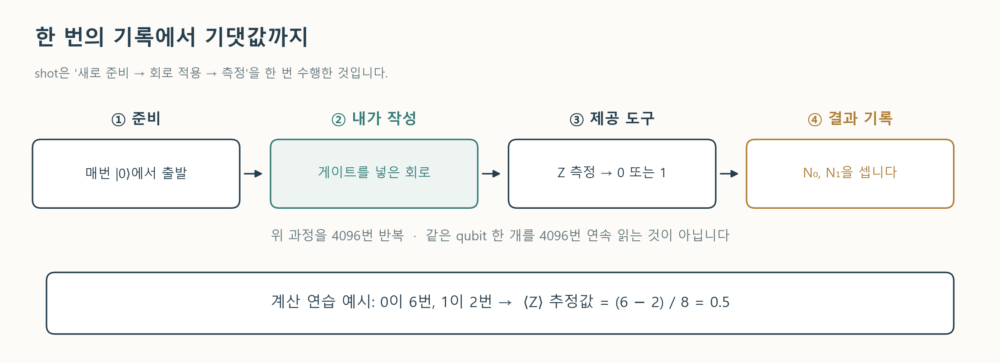

*8-shot 계산 예시. 실제 실험은 4096 shots.*


In [ ]:
# 직접 작성 1-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_1():
    "|0>에 X 한 번. 1-qubit 측정 없는 회로 반환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_1")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-1 — 회로·counts·Z 기댓값 확인
result_1_1 = run_if_ready(lambda: inspect_one(build_circuit_1_1))

**실험 메모 1-1 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 1-2. 기준 상태 점검 — H와 측정 통계 · 3점

`build_circuit_1_2()`에서 초기 상태 $|0\rangle$에 **H를 한 번** 적용하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다.

아래 **「실행 1-2 — H 실험과 1-1 비교」** 셀은 반환 회로의 복사본에 Z 기저 측정을 추가하여 4096회 실행합니다. 회로 그림에는 측정 전 회로만 표시됩니다. counts를 총 shots 수로 나누어 각 측정 결과의 상대도수를 구하고, 이론적 측정 확률과 비교하세요. 출력된 Z 기댓값 추정치도 이론값 및 1-1의 결과와 비교하세요.

**채점 사항:** 반환 회로의 크기·허용 게이트와 준비 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 H 하나여야 하며, 최종 상태가 같아지는 추가 게이트도 허용하지 않습니다. 4096-shot 출력은 관찰용이며, 특정 counts와의 일치는 요구하지 않습니다.


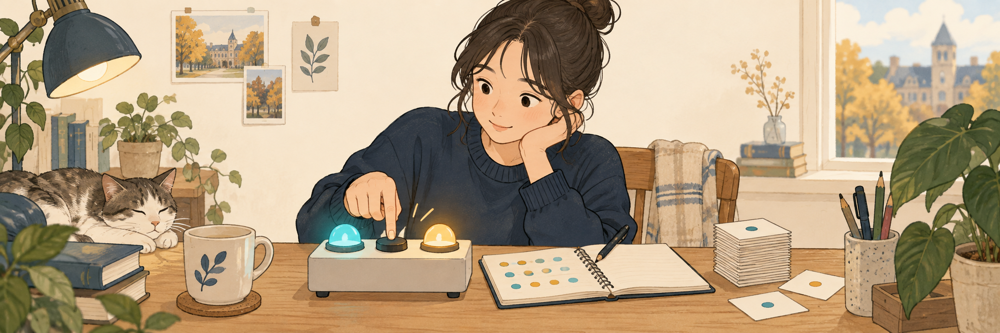

*반복 관찰의 삽화.*


In [ ]:
# 직접 작성 1-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_2():
    "|0>에 H 한 번. 1-qubit 측정 없는 회로 반환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_2")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-2 — H 실험과 1-1 비교
result_1_2 = run_if_ready(lambda: inspect_one(build_circuit_1_2))

**실험 메모 1-2 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 1-3. 기준 상태 점검 — H 두 번 · 4점

`build_circuit_1_3(initial_state)`에 제공된 초기 회로에 **H 게이트를 두 번 차례로 적용**하세요. 기존 초기화 부분을 유지한 측정 없는 `QuantumCircuit(1)`을 반환합니다. `initial_state`는 `"0"`, `"1"`, `"+"`, `"-"` 중 하나입니다.

아래 실행 셀은 네 초기 상태에 H를 두 번 적용한 회로 뒤에 Z 기저 측정을 추가하여 기댓값을 추정합니다. 네 결과를 비교하고, H를 두 번 적용했을 때 각 상태가 어떻게 변하는지 실험 메모에 정리하세요. 또한 네 초기 상태 중 서로 다르지만 같은 이론적 Z 측정 분포를 갖는 상태를 찾으세요.

**채점 사항:** 네 입력에 대한 초기 상태 준비와 최종 상태를 검사합니다. `barrier`를 제외한 전체 게이트 목록은 제공된 초기화 연산 뒤에 H 두 개를 차례로 붙인 형태여야 합니다. 최종 상태가 같더라도 초기화 연산을 바꾸거나 다른 게이트를 추가하면 이 조건을 충족하지 못합니다.


In [ ]:
# 직접 작성 1-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_circuit_1_3(initial_state):
    qc = initial_one_qubit(initial_state)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_circuit_1_3")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-3 — 네 초기 상태 비교
result_1_3 = run_if_ready(lambda: inspect_four_states(build_circuit_1_3, draw=True))

**실험 메모 1-3 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 1-4. 측정 기저로 상태 구별하기 · 5점

$|+\rangle$와 $|-\rangle$를 구별하는 공통 1-qubit 변환 `discrimination_basis()`를 설계하세요. 측정이 없는 `QuantumCircuit(1)`을 반환합니다. 이 함수는 후보 정보를 입력받지 않습니다. 제공 실험 코드는 모든 후보 상태에 같은 변환을 적용한 뒤 Z 기저로 측정합니다.

네 후보 `0`, `1`, `+`, `-` 각각에 대해, **변환 없이 Z를 측정한 기댓값**과 **여러분의 변환을 적용한 뒤 Z를 측정한 기댓값**을 비교하세요. 두 측정 설정에는 각각 새로 준비한 상태를 사용합니다. 다음 두 경우에 상태를 판별할 수 있는 조건이 어떻게 다른지 실험 메모에 적으세요.

1. 같은 후보 상태를 여러 번 준비해 두 측정 설정의 통계를 비교하는 경우
2. 네 후보 중 하나로 준비된 상태를, 어느 후보인지 모른 채 한 사본만 받는 경우

**힌트:** Z 측정 직전의 변환 $V$는 원래 상태의 $V^\dagger ZV$ 측정과 같습니다. $HZH=X$를 이용하세요.

**채점 사항:** 공통 국소 변환이 `+`와 `-`를 구별하는지 확인합니다. 측정 결과의 부호가 뒤집힌 동등한 구현도 허용합니다.


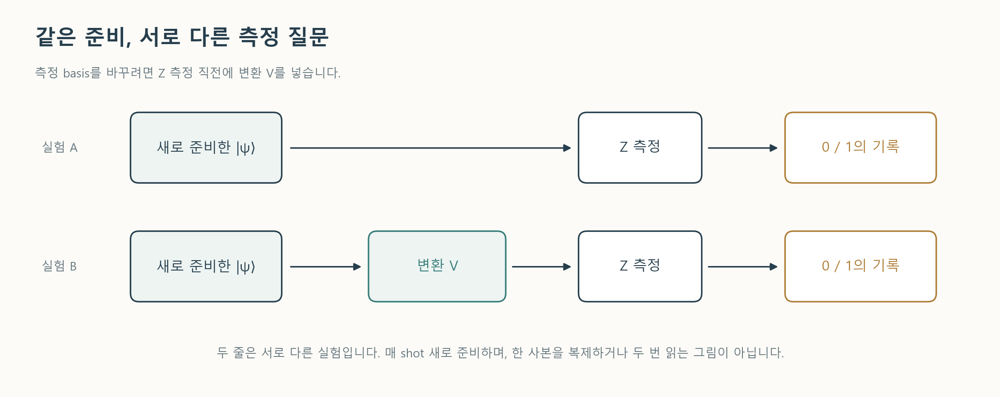

*두 실험은 각각 새로 준비한 상태를 사용합니다.*


In [ ]:
# 직접 작성 1-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def discrimination_basis():
    "어떤 후보인지 알 수 없는 1-qubit 공통 basis 변환. 측정 없음"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("discrimination_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-4 — 기존 측정과 새 측정 비교
def inspect_discrimination():
    readout = validate_fragment(discrimination_basis(), 1, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    print("Z readout")
    inspect_four_states(initial_one_qubit)
    print("New readout on fresh copies")
    return inspect_four_states(initial_one_qubit, readout)

result_1_4 = run_if_ready(inspect_discrimination)

**실험 메모 1-4 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 1-5. 전송 자원 준비 — 네 가지 Bell 상태 · 7점

고정 초기 상태 $|q_1q_0\rangle=|01\rangle$ 뒤에 붙일 `bell_transform(target)`를 작성하세요. 함수는 **변환 부분만 담은** 측정 없는 `QuantumCircuit(2)`를 반환합니다. 초기 X는 제공 코드가 적용합니다. `target`은 `"Phi+"`, `"Phi-"`, `"Psi+"`, `"Psi-"`입니다.

$$|\Phi^\pm\rangle=\frac{|00\rangle\pm|11\rangle}{\sqrt2},\qquad
|\Psi^\pm\rangle=\frac{|01\rangle\pm|10\rangle}{\sqrt2}.$$

아래 **「실행 1-5 — 네 Bell 목표 확인」** 셀에서 각 회로가 준비한 상태와 해당 목표 Bell 상태 사이의 fidelity를 확인하세요. 이 셀은 회로 그림과 fidelity를 출력합니다. 각 Bell 상태의 ⟨ZZ⟩와 ⟨XX⟩ 이론값을 직접 계산하세요. 이어서 Φ 계열과 Ψ 계열 각각에서 +와 − 상태를 비교하고, 상대 위상의 차이가 두 기댓값에 어떤 차이를 만드는지 실험 메모에 적으세요.

**채점 사항:** 지정 초기 상태에 반환 회로를 연결했을 때 네 목표 상태가 준비되는지 확인합니다. 전역 위상 차이는 무시하며, 같은 목표 상태를 준비하는 다른 회로 구현도 허용합니다.


In [ ]:
# 직접 작성 1-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bell_transform(target):
    "고정된 |01> 뒤에 붙일 2-qubit 변환 회로"
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bell_transform")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-5 — 네 Bell 목표 확인
run_if_ready(lambda: inspect_bells(bell_transform))

**실험 메모 1-5 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 1-6. 공유 자원 검수 — 같은 Z 측정 분포를 갖는 두 장치 · 8점

세 실험실에 배분할 두 공유 자원을 비교합니다.

- **장치 A:** $|GHZ^+\rangle=(|000\rangle+|111\rangle)/\sqrt2$를 준비합니다.
- **장치 B:** 공정한 동전 결과에 따라 000 또는 111을 준비하고 그 결과를 숨깁니다.

`build_ghz_state()`는 측정 없는 `QuantumCircuit(3)`, `build_coin_flip_state()`는 측정 없는 `QuantumCircuit(4)`를 반환해야 합니다. 장치 B의 q3는 상태를 준비한 뒤에는 접근할 수 없는 기록계입니다. q3를 제외한 q0~q2의 상태가 위에서 설명한 동전 장치의 상태와 같아야 합니다.

두 장치의 측정 결과 분포에 차이가 드러나도록 국소 변환 `correlation_basis()`를 설계하세요. 이 함수는 H/X/Z만 사용한 측정 없는 `QuantumCircuit(3)`을 반환합니다. **장치 A와 B의 q0·q1·q2에 같은 변환 회로를 적용**하며, 각 qubit에 적용하는 국소 연산은 서로 달라도 됩니다.

첫 번째 실행 셀에서는 변환 없이 Z 기저로 측정한 두 장치의 분포를 비교하세요. 두 번째 실행 셀에서는 제공 코드가 여러분의 변환 코드 뒤에 Z 기저 측정을 추가합니다. 한 shot의 세 결과가 $a,b,c$일 때 부호곱을 $(-1)^{a+b+c}$로 정의합니다. 즉 1의 개수가 짝수이면 +1, 홀수이면 −1이며, 출력의 **parity 기댓값은 이 부호곱의 표본평균**입니다. 두 장치의 값을 비교하세요. 같은 이론적 분포를 갖더라도 유한 shots에서 얻은 counts가 서로 정확히 일치할 필요는 없습니다.

**힌트:** B는 q3에 H를 적용한 뒤 q3에서 q0·q1·q2로 CX를 걸어 준비할 수 있습니다. q3의 결과로 표본을 고르지 마세요.

**채점 사항:** GHZ 상태가 올바르게 준비되는지, 기록계를 제외한 동전 장치의 상태가 요구한 혼합 상태인지, 같은 국소 측정으로 두 장치의 차이가 드러나는지 확인합니다.

**실험 메모 · 채점 제외:** ⟨XXX⟩ 하나만으로 임의의 상태를 GHZ라고 인증할 수 있는지도 생각해 보세요.


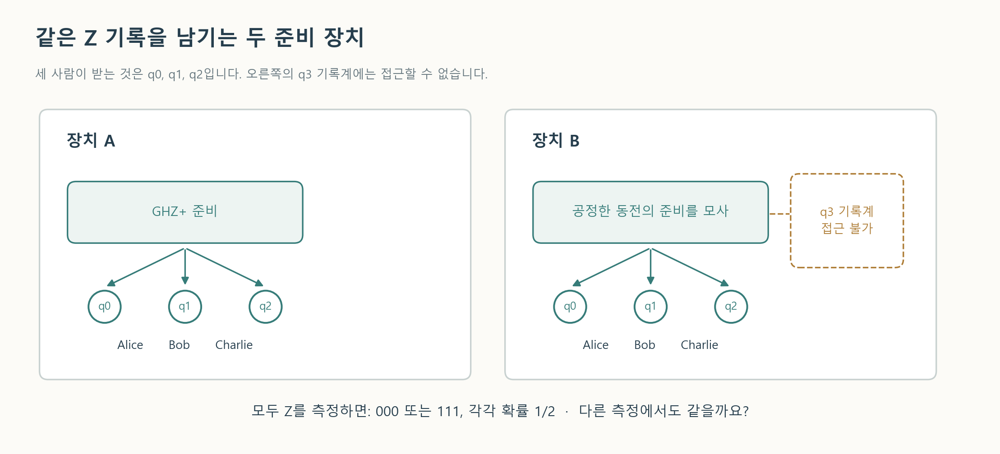

*q3는 접근 불가 기록계입니다.*


In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_ghz_state():
    "3-qubit GHZ+ 준비 회로. 측정 없음"
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_ghz_state")
    # TODO END
    return qc


In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_coin_flip_state():
    "q3를 무시하면 동전 장치가 되는 4-qubit 준비 회로"
    qc = QuantumCircuit(4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_coin_flip_state")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-6 — 준비 확인 — 두 장치의 상태·Z 통계
def inspect_source_preparations():
    display(validate_fragment(build_ghz_state(), 3).draw("mpl"))
    display(validate_fragment(build_coin_flip_state(), 4).draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state)

source_z_results = run_if_ready(inspect_source_preparations)

In [ ]:
# 직접 작성 1-6 — TODO BEGIN과 TODO END 사이만 작성하세요.
def correlation_basis():
    "장치 A/B에 공통 적용하는 3-qubit 국소 basis 변환"
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("correlation_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 1-6 — 판별 실험 — 같은 측정으로 차이 확인
def inspect_source_difference():
    readout = validate_fragment(correlation_basis(), 3, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state, readout)

source_parity_results = run_if_ready(inspect_source_difference)

**실험 메모 1-6 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


<a id="part2"></a>

# 2. 양자 텔레포테이션 — 전송 시험

**목표:** 일부 입력에서 실패하는 장치를 복구하여 Alice의 미지 양자 상태를 Bob에게 전달합니다.
입력 qubit을 직접 보낼 수 없으며, 미리 공유한 Bell pair와 고전 bit 2개를 사용합니다.
오류 재현 → 회로 복구 → 전송 검증 → 교체 자원에 맞춘 조정 순서로 진행하세요.


In [ ]:
#@title 준비 2 — 전송 실험 도구
def protocol_1q(pair, alice, bob):
    """Fixed routing: q0=payload, q1=Alice resource, q2=Bob; c0,c1=Alice results."""
    validate_fragment(pair, 2)
    validate_fragment(alice, 2)
    validate_fragment(bob, 1, 2, ("h", "x", "z"), True)
    qc = QuantumCircuit(3, 2)
    qc.compose(pair, [1, 2], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 1], inplace=True)
    qc.measure([0, 1], [0, 1])
    qc.compose(bob, [2], [0, 1], inplace=True)
    return qc

def probe_states():
    states = {}
    for label, gates in [("0", []), ("1", ["x"]), ("+", ["h"]),
                         ("-", ["x", "h"]), ("+i", ["h", "s"]), ("-i", ["h", "sdg"])]:
        qc = QuantumCircuit(1)
        for gate in gates:
            getattr(qc, gate)(0)
        states[label] = qc
    return states

def haar_prep(seed, n=1):
    """Haar-random pure state in dimension 2**n, including entangled states for n=2."""
    rng = np.random.default_rng(seed)
    vector = rng.normal(size=2**n) + 1j * rng.normal(size=2**n)
    vector /= np.linalg.norm(vector)
    qc = QuantumCircuit(n)
    qc.prepare_state(vector, list(range(n)))
    return qc

def sample_fidelity(protocol, prep, inputs=(0,), outputs=(2,), shots=SHOTS, seed=SEED):
    """The referee, not the participant's protocol, prepares U|0> and verifies with U^-1."""
    if prep.num_qubits != len(inputs) or len(inputs) != len(outputs):
        raise ValueError("Input/output dimensions do not match")
    qc = QuantumCircuit(protocol.num_qubits, protocol.num_clbits)
    qc.compose(prep, list(inputs), inplace=True)
    qc.compose(protocol, inplace=True)
    verify = ClassicalRegister(len(outputs), "verify")
    qc.add_register(verify)
    qc.compose(prep.inverse(), list(outputs), inplace=True)
    qc.measure(list(outputs), verify)
    counts = BACKEND.run(compile_for_aer(qc, seed),
                         shots=shots, seed_simulator=seed).result().get_counts()
    indices = [qc.find_bit(bit).index for bit in verify]
    successes = 0
    branches = {}
    for key, count in counts.items():
        ok = all(bit_at(key, i) == 0 for i in indices)
        successes += count * ok
        label = "".join(str(bit_at(key, i)) for i in reversed(range(protocol.num_clbits)))
        good, total = branches.get(label, (0, 0))
        branches[label] = (good + count * ok, total + count)
    return {"fidelity": successes / shots,
            "branches": {k: {"shots": n, "fidelity": g/n} for k, (g, n) in sorted(branches.items())}}

def public_teleport_check(protocol, n=1, random_count=20):
    inputs, outputs = ((0,), (2,)) if n == 1 else ((0, 1), (4, 5))
    cases = probe_states() if n == 1 else {}
    cases.update({f"Haar {s}": haar_prep(s, n) for s in range(random_count)})
    scores = []
    for i, (label, prep) in enumerate(cases.items()):
        result = sample_fidelity(protocol, prep, inputs, outputs, seed=SEED+i)
        scores.append(result["fidelity"])
        if i < 6:
            print(f"{label:>8s}: F_hat={scores[-1]:.6f}")
    print(f"{len(scores)} states: mean={np.mean(scores):.6f}, min={min(scores):.6f}")
    return scores

def broken_parts():
    pair = QuantumCircuit(2)
    pair.h(0)
    pair.cx(0, 1)
    alice = QuantumCircuit(2)
    alice.cx(0, 1)
    alice.h(0)
    bob = QuantumCircuit(1, 2)
    with bob.if_test((bob.clbits[0], 1)):
        bob.x(0)
    with bob.if_test((bob.clbits[1], 1)):
        bob.z(0)
    return pair, alice, bob

def graph_pair():
    """Fixed resource: CZ|++>; CZ is expanded using H,CX,H."""
    qc = QuantumCircuit(2)
    qc.h(1)  # Bob's state BEFORE entanglement generation
    qc.h(0)
    qc.h(1)
    qc.cx(0, 1)
    qc.h(1)
    return qc

def protocol_2q(pair4, alice, bob2):
    """Resource local indices [A0,A1,B0,B1] -> global [2,3,4,5]."""
    validate_fragment(pair4, 4)
    validate_fragment(alice, 2)
    validate_fragment(bob2, 2, 4, ("h", "x", "z"), True)
    qc = QuantumCircuit(6, 4)
    qc.compose(pair4, [2, 3, 4, 5], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 2], inplace=True)
    qc.compose(alice, [1, 3], inplace=True)
    qc.measure([0, 2, 1, 3], [0, 1, 2, 3])
    qc.compose(bob2, [4, 5], [0, 1, 2, 3], inplace=True)
    return qc

def report_transfer_check(report, case, exercise):
    """Show a real failed assertion without interrupting the rest of the workbook."""
    from html import escape
    from IPython.display import HTML, display
    observed = report["fidelity"]
    message = (f"[QFF-{exercise}] 입력: {case}. "
               f"이상적 전송 검증 실패: expected F_hat=1.000000, observed F_hat={observed:.6f}.")
    try:
        assert observed == 1.0, message
    except AssertionError as error:
        display(HTML('<div style="border-left:5px solid #b44b40;background:#fff1ef;padding:14px 18px;">'
                     '<b>검증 실패 · AssertionError</b><pre style="white-space:pre-wrap;">'
                     + escape(str(error)) + '</pre>'
                     '<p>의도된 디버깅 실험입니다. 설치 오류가 아닙니다. '
                     '실패한 입력과 결과를 기록하고, 아래 회로에서 원인을 추적하세요.</p></div>'))
        return False
    print(f"[QFF-{exercise}] PASS — {case}: F_hat={observed:.6f}")
    return True

**전송 자원·배선**

총 3 qubit: `q0=Q`(미지 입력), `q1=A`, `q2=B`.
전송 자원은 배분 전에 준비한 A–B Bell pair 1쌍입니다. 배분 후에는 각자 국소 연산과 Alice→Bob **고전 bit 2개**만 허용합니다.
측정은 `Q→c0`, `A→c1`; 결과 문자열은 **c1 c0**입니다.

| 함수 | 반환 회로 | 로컬 인덱스 |
|---|---|---|
| `shared_pair()` | 2 qubit · 0 cbit | 0=A, 1=B; 초기 00 |
| `alice_encoder()` | 2 qubit · 0 cbit | 0=Q, 1=A |
| `bob_decoder()` | 1 qubit · 2 cbit | q0=B; c0,c1=Alice 결과 |

참가자가 작성하는 전송 함수에는 미지 입력의 진폭이나 입력을 준비한 회로가 제공되지 않습니다. 제공 검증 코드(심판)는 입력 준비 연산을 알고 있으며, 전송 후 그 역연산을 적용하여 복구 여부를 확인합니다. 전송의 목표는 모든 입력·측정 분기에서 F=1입니다.

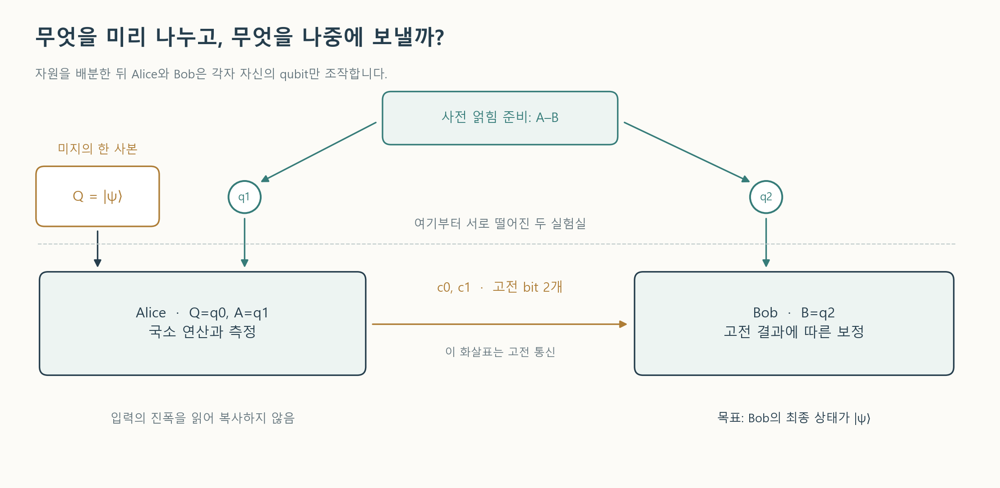

*배분 후 화살표는 고전 통신입니다.*


## 2-1. 오류 재현과 진단 · 6점

**먼저 아래 「실행 2-1 — 먼저 눌러 고장 재현 — 오류 메시지에서 출발」 셀을 실행하여 제공된 고장 회로의 `AssertionError` 메시지를 확인하세요.** 이 실패 메시지는 의도된 디버깅 결과입니다. 여섯 입력 `0`, `1`, `+`, `-`, `+i`, `-i`와 `+` 입력의 네 측정 분기를 비교해 결함을 찾으세요. 수정 회로는 2-2에 구현합니다.

아래 TODO 코드 셀에서 `teleportation_diagnosis()`를 구현하세요.

**반환 형식:** `(failed_inputs, masked_inputs, plus_branch_fidelities)`

| 반환 항목 | 내용과 순서 |
|---|---|
| `failed_inputs` | 고장 회로의 평균 fidelity가 1보다 작은 입력 라벨의 tuple |
| `masked_inputs` | 고장 회로의 평균 fidelity가 1이라 결함이 가려지는 입력 라벨의 tuple |
| `plus_branch_fidelities` | `+` 입력에서 결과 `c1 c0 = 00, 01, 10, 11`에 대응하는 조건부 fidelity 4개의 tuple |

위의 여섯 입력 라벨을 `failed_inputs`와 `masked_inputs`에 빠짐없이 한 번씩 나누어 담으세요. 두 tuple 안에서 라벨을 나열하는 순서는 자유롭습니다. 여기서 평균은 **측정 분기 확률을 반영한 평균**입니다. 조건부 fidelity는 해당 분기 상태를 정규화한 뒤 입력 상태와 비교한 값입니다. 아래 실험의 표본값을 복사하지 말고, 제공된 고장 회로로부터 정확한 값을 계산하세요.

**채점 사항:** 여섯 입력의 분류와 네 분기의 수치 결과. 실패 메시지와 원인 설명은 실험 메모에 남깁니다.


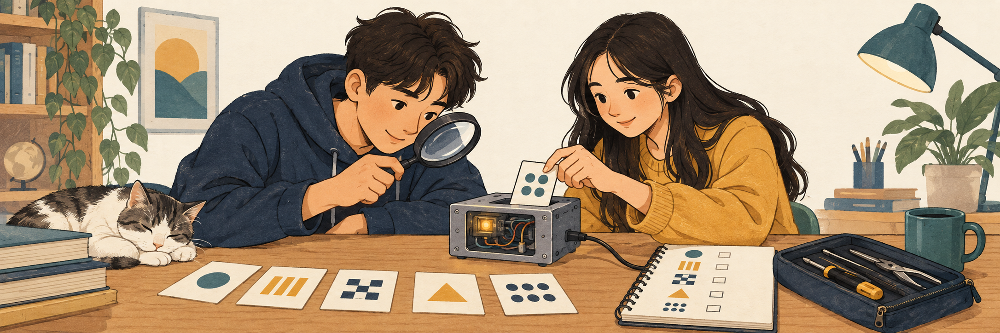

*서로 다른 입력으로 결함을 진단합니다.*


In [ ]:
with _qff_experiment("제공 실험 38"):
    #@title 실행 2-1 — 먼저 눌러 고장 재현 — 오류 메시지에서 출발
    # 먼저 ▶를 누르세요. 이 셀은 실패 증상을 재현하는 제공 코드입니다.
    # 원인을 찾은 뒤, 수정한 세 회로는 2-2의 '직접 작성' 셀에 구현합니다.
    pair_bad = QuantumCircuit(2)
    pair_bad.h(0)
    pair_bad.cx(0, 1)
    
    alice_bad = QuantumCircuit(2)
    alice_bad.cx(0, 1)
    alice_bad.h(0)
    
    bob_bad = QuantumCircuit(1, 2)
    with bob_bad.if_test((bob_bad.clbits[0], 1)):
        bob_bad.x(0)
    with bob_bad.if_test((bob_bad.clbits[1], 1)):
        bob_bad.z(0)
    
    broken = protocol_1q(pair_bad, alice_bad, bob_bad)
    debug_report_2_1 = sample_fidelity(broken, probe_states()["+"])
    debug_passed_2_1 = report_transfer_check(debug_report_2_1, "|+>", "2-1")
    display(broken.draw("mpl", fold=100, cregbundle=False))
    print("추가 단서: 여섯 입력을 같은 회로에 보낸 결과")
    for label, prep in probe_states().items():
        print(label, sample_fidelity(broken, prep)["fidelity"])
    print("|+> branch report (c1 c0):")
    show_fidelity(debug_report_2_1)


In [ ]:
# 직접 작성 2-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def teleportation_diagnosis():
    failed_inputs = masked_inputs = plus_branch_fidelities = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("teleportation_diagnosis")
    # TODO END
    return failed_inputs, masked_inputs, plus_branch_fidelities


**실험 메모 2-1 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 2-2. 전송 회로 복구 · 18점

`shared_pair()`, `alice_encoder()`, `bob_decoder()`를 완성해 **모든 입력·측정 분기에서 $F=1$**인 전송을 구현하세요. 각 함수가 반환하는 회로의 qubit·고전 비트 수와 로컬 인덱스는 위 「전송 자원·배선」 표를 따릅니다.

- `shared_pair()`는 00에서 $|\Phi^+\rangle$를 준비합니다.
- `alice_encoder()`는 로컬 `[Q, A]`의 측정 전 연산을 반환합니다.
- `bob_decoder()`는 `QuantumCircuit(1, 2)`를 반환합니다. q0는 Bob, c0·c1은 Alice의 측정 결과이며, H/X/Z와 `if_test`를 사용합니다.

`if_test`는 `with qc.if_test((qc.clbits[i], 1)):`처럼 **이 회로의 고전 비트 하나를 0 또는 1과 비교**하는 조건으로 작성하세요. 여러 비트의 조건이 필요하면 `if_test`를 중첩할 수 있습니다. `qc.cregs[0]` 같은 고전 레지스터 전체를 정수와 비교하거나, 고전 논리식을 조건으로 사용하는 방식은 허용하지 않습니다. 이 제한은 2-4(b)와 선택 2-5의 Bob 보정에도 동일하게 적용됩니다.

아래 「실행 2-2 — 수정 후 재검증 — 복구 회로와 전송 fidelity」 셀은 세 회로를 연결하고 Alice의 측정을 추가하여, Bob의 보정 후 전송 fidelity를 표본으로 추정합니다. 이 출력으로 복구 결과를 확인하세요. 실험 메모에는 별도로 각 측정 결과 `c1 c0`에 대한 Bob의 보정 전 상태를 계산하고, 적용한 보정 연산과 함께 정리하세요. X·Z 보정 순서를 바꿀 때 생기는 차이도 살펴보세요.

**채점 사항:** Bell 자원 준비와 전체 전송 채널. 임의의 미지 입력을 모든 측정 분기에서 복구하는지 확인하며, 같은 동작을 하는 다른 회로·보정 순서도 허용합니다.


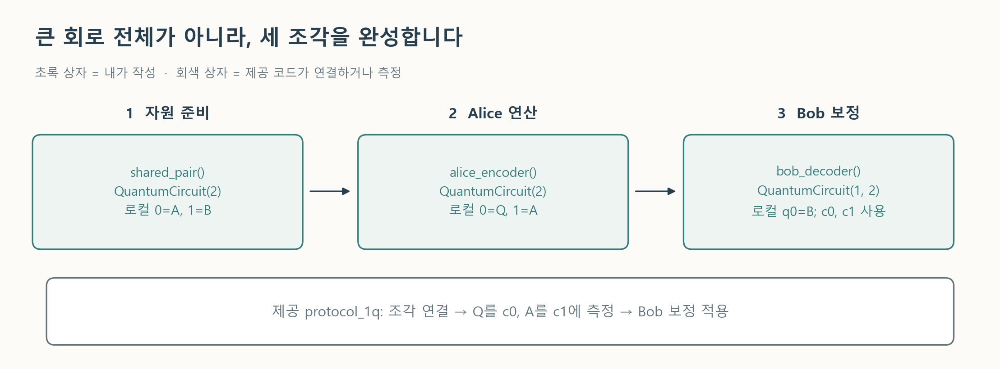

*각 함수의 로컬 인덱스에 주의하세요.*


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def shared_pair():
    "00에서 Phi+를 준비하는 2-qubit 회로"
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("shared_pair")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def alice_encoder():
    "Q,A 순서의 2-qubit 회로. 측정은 넣지 마세요."
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("alice_encoder")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_decoder():
    "QuantumCircuit(1, 2), q0=Bob, c0/c1=Alice 결과"
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_decoder")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-2 — 수정 후 재검증 — 복구 회로와 전송 fidelity
def inspect_fixed():
    protocol = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

fixed_results = run_if_ready(inspect_fixed)

**실험 메모 2-2 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 2-3. 전송 검증의 의미 · 7점

2-2의 「실행 2-2 — 수정 후 재검증 — 복구 회로와 전송 fidelity」 셀은 여섯 기준 상태와 Haar 무작위 상태 20개에 대한 전송 fidelity를 표본으로 추정합니다. 출력된 평균·최소 fidelity를 확인한 뒤, 아래 TODO 코드 셀에서 `teleportation_validation()`을 구현하세요. `mean_F`와 `min_F`는 **2-2에서 올바르게 복구한 전송 회로**를 대상으로 정확한 값을 계산합니다. `bob_average_density`는 아래 설명에 따라 **정상적인 전송에서의 보정 전 평균 상태**를 계산합니다.

**반환 형식:** `(mean_F, min_F, bob_average_density)`

| 반환 항목 | 계산 대상 |
|---|---|
| `mean_F` | `probe_states()`의 여섯 상태와 `haar_prep(seed)`의 `seed=0, …, 19`에 대한 보정 후 이상적 fidelity 26개의 산술평균 |
| `min_F` | 같은 26개 fidelity의 최솟값 |
| `bob_average_density` | 정상적인 전송에서 Alice의 고전 결과를 받기 전, 측정 분기 확률로 평균한 Bob의 2×2 밀도행렬 |

각 입력 상태 $|\psi\rangle$에 대해, Alice의 측정 결과별로 **Bob의 보정을 적용한 뒤 Bob의 밀도행렬을 구하세요.** 이 밀도행렬들을 각 측정 결과의 발생 확률로 가중 평균하여 $\rho_B$를 구하세요. 이 입력의 fidelity는 입력 상태와 보정 후 Bob 상태를 비교한 $\langle\psi|\rho_B|\psi\rangle$입니다.

`bob_average_density`는 **2-2의 전송 조건을 만족하는 정상적인 회로를 기준으로** 계산하세요. **Bob의 보정을 적용하기 전** 각 측정 분기에서의 Bob의 밀도행렬을 구하세요. 이를 각 분기의 발생 확률로 가중 평균한 밀도행렬을 반환하세요. 이 항목의 계산에는 기준 입력 `0`을 사용합니다. 올바른 전송에서는 미지 입력을 바꾸어도 이 평균 상태가 같아야 합니다. 행·열 순서는 `0, 1`입니다. 행렬은 NumPy 배열 또는 중첩 수열로 반환할 수 있습니다. 복소수 자료형으로 계산했다면 그대로 반환하거나, 수치 오차 수준의 허수부를 제거해도 됩니다.

**채점 사항:** 정확한 평균·최소 fidelity와 Bob의 평균 상태를 검사합니다. `mean_F`와 `min_F`는 2-2의 전송 회로가 모든 입력·측정 분기에서 입력 상태를 복구하는 조건을 만족해야 채점합니다. `bob_average_density`는 **정상적인 전송에서의 이론적 평균 상태**를 기준으로, 2-2의 통과 여부와 독립적으로 채점합니다. 따라서 2-2가 미완성이어도 정상 전송에서의 평균 상태를 계산해 제출할 수 있습니다. 작성 중인 오답 회로의 실제 평균 상태는 이 항목의 계산 대상이 아닙니다. 반환값에는 4096-shot 검증의 표본 추정치를 사용하지 않습니다.

실험 메모에서는 다음을 설명해 보세요. 제공 검증 코드(심판)가 $U|0\rangle=|\psi\rangle$를 준비하고 Bob 출력에 $U^\dagger$를 적용할 때 왜 $P(0)=\langle\psi|\rho_B|\psi\rangle$일까요? 입력을 모르는 Bob도 같은 검증을 할 수 있을까요? 이상적 전송에서 유한한 측정 횟수로 얻은 fidelity 추정값이 정확히 1이 될 수 있는지 생각해 보세요. 또한 Alice의 고전 측정 결과가 전달되기 전에는, Alice가 입력 상태를 달리 준비하는 방식으로 Bob에게 정보를 전달할 수 없는 이유를 설명해 보세요.


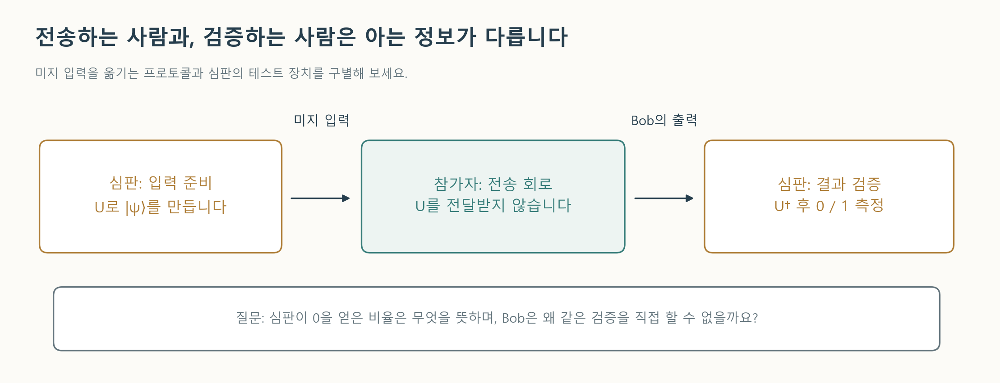

*제공 검증 코드가 U와 U†를 사용합니다. 참가자가 작성하는 전송 함수에는 입력 준비 정보가 제공되지 않습니다.*


In [ ]:
# 직접 작성 2-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def teleportation_validation():
    mean_F = min_F = bob_average_density = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("teleportation_validation")
    # TODO END
    return mean_F, min_F, bob_average_density


**실험 메모 2-3 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 2-4. 교체 자원에 맞춰 장치 조정 · 9점

**(a) 초기 상태가 달라졌을 때의 Bell pair 준비**

얽힘 생성 전 초기 상태는 $|0\rangle_A|+\rangle_B$입니다. 아래 「실행 2-4 — 자원 비교 — 준비 방식 확인」 셀에서 이 초기 상태에 H(A)와 CX(A,B)를 차례로 적용한 결과를 관찰하고, 얽힘이 만들어지는지 확인하세요. 이어 같은 초기 상태를 $|\Phi^+\rangle$로 바꾸는 변환 회로를 `bell_pair_from_b_plus()`에 구현하세요.

반환값은 **초기 상태 뒤에 붙일 변환 전체를 담은** 측정 없는 `QuantumCircuit(2)`입니다. 로컬 q0=A, q1=B이며 H/X/Z/CX를 사용할 수 있습니다. 변환 안에서 게이트를 적용하는 순서는 직접 결정하세요. 초기 B의 `+` 준비는 채점 코드가 먼저 적용합니다. 목표 상태는 $|\Phi^+\rangle$입니다.

**실행 셀의 확인 범위:** 「실행 2-4 — 자원 비교 — 준비 방식 확인」은 제공된 고정 회로를 비교하며, `bell_pair_from_b_plus()`를 호출하지 않습니다. 뒤의 「실행 2-4 — 보정 확인 — graph 자원 전송」도 (b)의 전송만 확인합니다. 두 실행 셀이 정상 출력되어도 (a)의 답안이 검증된 것은 아닙니다. **`bell_pair_from_b_plus()`의 반환 회로는 마지막 채점 셀에서 검사합니다.**

**(b) Graph 자원의 보정**

고정 자원 $|G\rangle=CZ|++\rangle=(I_A\otimes H_B)|\Phi^+\rangle$에 맞는 `bob_graph_decoder()`를 작성하세요. `graph_pair()`와 **2-2에서 작성한 Alice 연산**을 그대로 사용합니다. `bob_graph_decoder()`도 `bob_decoder()`와 마찬가지로 `QuantumCircuit(1, 2)`를 반환하며, H/X/Z와 `if_test`만 사용할 수 있습니다. `if_test`에는 2-2와 같은 단일 로컬 고전 비트의 0/1 조건만 사용하세요. 위 텐서 표기는 A,B 순서입니다.

**채점 사항:** (a)의 Bell 준비와 (b)의 모든 입력·측정 분기 전송. 보정 순서와 자원 교체의 의미는 실험 메모에 적습니다.


In [ ]:
# 직접 작성 2-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bell_pair_from_b_plus():
    qc = QuantumCircuit(2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bell_pair_from_b_plus")
    # TODO END
    return qc


In [ ]:
with _qff_experiment("제공 실험 49"):
    #@title 실행 2-4 — 자원 비교 — 준비 방식 확인
    plus_attempt = QuantumCircuit(2)
    plus_attempt.h(1)
    plus_attempt.h(0)
    plus_attempt.cx(0, 1)
    print("CX attempt, Bob purity:", partial_trace(Statevector(plus_attempt), [0]).purity().real)
    print("Graph resource, Bob purity:", partial_trace(Statevector(graph_pair()), [0]).purity().real)
    display(graph_pair().draw("mpl"))


In [ ]:
# 직접 작성 2-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_graph_decoder():
    "고정 graph 자원용 QuantumCircuit(1, 2). H,X,Z와 if_test 허용"
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_graph_decoder")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-4 — 보정 확인 — graph 자원 전송
def inspect_graph():
    protocol = protocol_1q(graph_pair(), alice_encoder(), bob_graph_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

graph_results = run_if_ready(inspect_graph)

**실험 메모 2-4 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 연결 실험 — GHZ의 한 몫을 전달하라

복구한 장치가 얽힘도 보존하는지 확인합니다. Alice는 GHZ 상태를 이루는 qubit 중 q0와 q3를 가지고, Charlie는 q4를 가집니다. 이때 q0의 상태를 Bob의 q2로 전송합니다. 전송에 사용하는 Bell pair는 Alice의 q1과 Bob의 q2가 공유합니다.
아래 「연결 실험 — 복구한 회로로 GHZ의 한 몫 전송」 셀은 **1-6의 준비 함수와 2-2의 전송 함수**를 재사용합니다. 출력되는 두 값을 구분해 확인하세요.

- **입력 GHZ 준비 fidelity:** 1-6에서 준비한 입력 상태와 목표 GHZ 상태를 비교합니다.
- **전송 fidelity:** 전송 후 Alice(q3)·Bob(q2)·Charlie(q4)의 상태를, 여러분이 실제로 준비했던 입력 상태와 비교합니다. 세 qubit의 전체 상태가 얼마나 잘 보존되었는지를 표본 측정으로 추정한 값입니다.

GHZ 준비와 전송이 모두 올바른지 두 검증을 함께 확인하세요. 이 전송 자원은 3번의 연결 실험에서도 사용합니다.

*한 qubit만 보면 결과가 무작위입니다. 얽힘 전송의 성공은 세 qubit의 관계까지 검사해야 알 수 있습니다.*


In [ ]:
#@title 연결 실험 — 복구한 회로로 GHZ의 한 몫 전송
# 제공 코드: 새 함수를 작성하지 않고 1-6과 2-2의 결과를 연결합니다.
def linked_ghz_setup():
    prep = validate_fragment(build_ghz_state(), 3)
    transfer = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    protocol = QuantumCircuit(5, 2)
    protocol.compose(transfer, [0, 1, 2], [0, 1], inplace=True)
    return prep, protocol

def inspect_linked_ghz():
    prep, protocol = linked_ghz_setup()
    report = sample_fidelity(protocol, prep, inputs=(0, 3, 4), outputs=(2, 3, 4))
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("입력 GHZ 준비 fidelity:", state_fidelity(Statevector(prep), target))
    print("준비한 세 qubit 전체의 전송 fidelity (c1 c0의 모든 분기 포함)")
    show_fidelity(report)
    return report

linked_ghz_result = run_if_ready(inspect_linked_ghz)


**전송 시험 완료 기준:** Alice의 측정 결과에 따라 Bob의 상태를 보정하여 입력 상태를 복구하고, 입력이 다른 qubit과 맺고 있던 얽힘도 보존해야 합니다. 이제 세 실험실이 입력 이후 통신 없이 이 공유 자원을 활용하는지 시험합니다.


<a id="part3"></a>

# 3. GHZ–Mermin 게임 — 협력 시험

**목표:** 세 실험실이 각자 자기 입력만 보고도 공동 조건을 얼마나 자주 만족하는지 비교합니다.
한 라운드에서 공동 조건을 만족하면 **팀 전체가 1점**을 얻습니다. 점수가 높을수록 입력 이후 연락 없이도 올바른 공동 응답을 만드는 비율이 높습니다.

같은 bit를 내는 것이 목표는 아닙니다. 각자의 출력은 무작위여도 **세 출력의 관계**는 정확할 수 있습니다.
여기서 확인하는 것은 공유 자원과 측정 전략의 협력 성능이며, 전송 속도나 네트워크 전체의 보안 점수가 아닙니다.


In [ ]:
#@title 준비 3 — 게임 실험 도구
INPUTS = ((0,0,0), (0,1,1), (1,0,1), (1,1,0))
PARTIES = ("Alice", "Bob", "Charlie")

def winning_parity(x, y, z):
    if (x, y, z) not in INPUTS:
        raise ValueError("Only promised input triples are used")
    return ((x + y + z) // 2) % 2

def freeze_strategy(local_basis):
    """Build six local circuits once, BEFORE the referee selects any input triple."""
    table = {}
    for party in PARTIES:
        for bit in (0, 1):
            table[party, bit] = validate_fragment(
                local_basis(party, bit), 1, allowed=("h", "s", "sdg", "x", "z")).copy()
    return table

def game_unitary(resource, strategy, xyz):
    validate_fragment(resource, resource.num_qubits)
    if resource.num_qubits not in (3, 4):
        raise ValueError("Expected 3 players, with optional inaccessible q3")
    if xyz not in INPUTS:
        raise ValueError("Invalid input triple")
    qc = resource.copy()
    qc.barrier(label="inputs distributed")
    for q, (party, bit) in enumerate(zip(PARTIES, xyz)):
        fragment = validate_fragment(strategy[party, bit], 1,
                                     allowed=("h", "s", "sdg", "x", "z"))
        qc.compose(fragment, [q], inplace=True)
    return qc

def build_mermin_round(resource, strategy, xyz):
    qc = game_unitary(resource, strategy, xyz)
    out = ClassicalRegister(3, "out")
    qc.add_register(out)
    qc.measure([0, 1, 2], out)
    return qc

def sample_game(resource, strategy, shots=SHOTS, seed=SEED):
    rows = []
    circuits = [build_mermin_round(resource, strategy, xyz) for xyz in INPUTS]
    result = BACKEND.run(compile_for_aer(circuits, seed),
                         shots=shots, seed_simulator=seed).result()
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins = sum(n for key, n in counts.items()
                   if sum(map(int, key.replace(" ", ""))) % 2 == winning_parity(*xyz))
        ev = sum((-1)**sum(map(int, key.replace(" ", ""))) * n for key, n in counts.items())/shots
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": ev})
    # This is the game Bell expression for the submitted observables.
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def exact_game(resource, strategy):
    rows = []
    for xyz in INPUTS:
        probabilities = Statevector.from_instruction(game_unitary(resource, strategy, xyz)).probabilities([0, 1, 2])
        ev = sum((-1)**i.bit_count()*p for i, p in enumerate(probabilities))
        rows.append({"input": xyz, "win_rate": (1+(-1)**winning_parity(*xyz)*ev)/2, "correlator": ev})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def coin_resource():
    """q3 purifies the mixture and is inaccessible to all three players."""
    qc = QuantumCircuit(4)
    qc.h(3)
    for q in (0, 1, 2):
        qc.cx(3, q)
    return qc

def sample_linked_game(strategy, shots=SHOTS, seed=SEED):
    """Use all teleportation branches; only final game bits determine the score."""
    prep, protocol = linked_ghz_setup()
    circuits = []
    for xyz in INPUTS:
        qc = QuantumCircuit(5, 2)
        qc.compose(prep, [0, 3, 4], inplace=True)
        qc.compose(protocol, inplace=True)
        qc.barrier(label="inputs distributed")  # Transfer/corrections are already complete.
        for q, party, bit in zip((3, 2, 4), PARTIES, xyz):  # Alice, Bob, Charlie
            qc.compose(validate_fragment(strategy[party, bit], 1,
                       allowed=("h", "s", "sdg", "x", "z")), [q], inplace=True)
        out = ClassicalRegister(3, "out")
        qc.add_register(out)
        qc.measure([3, 2, 4], out)
        circuits.append(qc)
    result = BACKEND.run(compile_for_aer(circuits, seed), shots=shots,
                         seed_simulator=seed).result()
    rows = []
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins, signed = 0, 0
        for key, count in counts.items():
            parity = sum(bit_at(key, j) for j in (2, 3, 4)) % 2
            wins += count * (parity == winning_parity(*xyz))
            signed += count * (-1)**parity
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": signed/shots})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([row["win_rate"] for row in rows]), "M": m}


**게임 규칙**

입력 `xyz`는 `{000, 011, 101, 110}` 중 하나로 같은 확률로 정해집니다. 입력은 게임 전에 준비한 공유 자원과 독립적으로 선택됩니다.
각자는 자기 입력만 받습니다. 사전 합의·공유 난수는 허용하며 **입력 이후 통신은 금지**합니다.

$$a\oplus b\oplus c=\frac{x+y+z}{2}\pmod2$$

이면 승리합니다. parity는 **출력에 포함된 1의 개수가 짝수인지 홀수인지**입니다. 목표 출력 parity는 000에서 0, 나머지 세 입력에서 1입니다.
측정값이 +1이면 0, −1이면 1을 출력합니다. 직접 준비한 GHZ에서는 Alice, Bob, Charlie에게 각각 q0, q1, q2를 배정합니다. 연결 실험에서는 같은 순서로 q3, q2, q4를 사용합니다. 각자의 출력 bit를 a, b, c라고 하면, **게임 출력 비트는 `cba` 순서로 표시됩니다.** 직접 준비한 GHZ 실험의 원시 `counts` 키는 `cba` 형태입니다. 연결 실험에서는 텔레포테이션 측정 결과 두 비트가 함께 남아 있어 `cba c1c0` 형태로 표시됩니다. 뒤의 `c1c0`는 Alice의 텔레포테이션 측정 결과입니다. **게임의 parity와 승률을 계산할 때는 앞의 게임 출력 세 비트 `cba`만 사용하세요.** 제공 실험 코드도 이 세 비트만 사용합니다.
GHZ 준비 fidelity와 게임 승률을 각각 평가합니다.

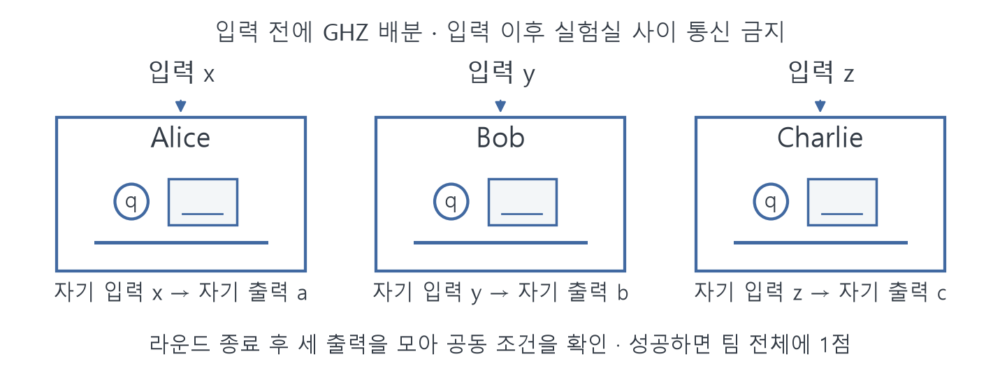

*점수 = 성공 라운드 수. 평균 승률 = 점수 ÷ 전체 라운드 수.*


## 3-1. 고전 전략의 한계 · 7점

한 사람의 전략을 `(입력0의 출력, 입력1의 출력)`으로 나타냅니다. `classical_search()`에서 세 사람의 **64개 결정론적 전략 조합을 조사**하고 `(최대 승률, (sa, sb, sc))`를 반환하세요. 각 전략은 입력이 0일 때와 1일 때 출력할 bit를 순서대로 담은 쌍입니다. `sa`, `sb`, `sc`는 각각 Alice, Bob, Charlie의 전략입니다. 승률은 네 허용 입력이 같은 확률로 주어질 때의 평균 승률입니다.

양자 전략이 좋은지 판단하려면 가장 좋은 고전 전략이 기준이 됩니다. 최적 전략의 예를 확인하고, 100% 성공이 불가능한 parity 논증과 공유 난수가 한계를 높이지 못하는 이유를 실험 메모에 적으세요.

**채점 사항:** 반환한 최대 승률, 해당 승률을 실제로 달성하는 전략, 두 결과의 일치. 같은 최댓값을 달성하는 다른 전략도 허용합니다.


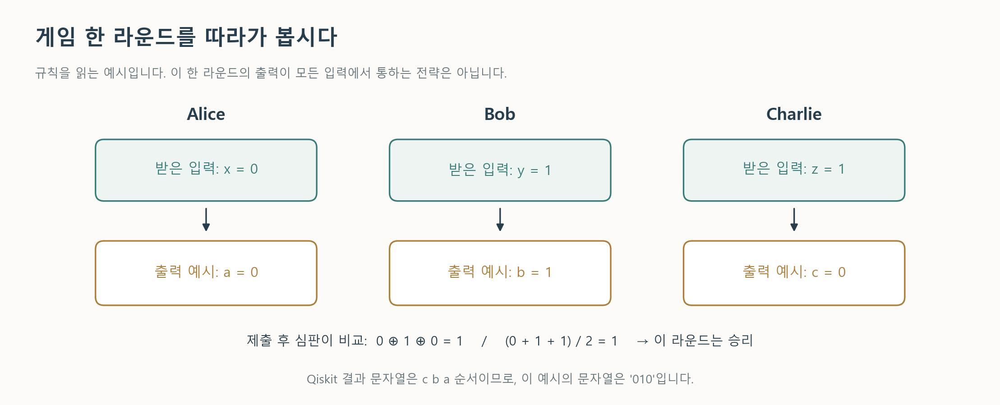

*단일 라운드의 예시이며 전체 입력에 대한 전략은 아닙니다.*


In [ ]:
# 직접 작성 3-1 — TODO BEGIN과 TODO END 사이만 작성하세요.
def classical_search():
    "64가지 조합을 확인하고 (best_probability, (sa,sb,sc)) 반환"
    best_probability = None
    sa = sb = sc = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("classical_search")
    # TODO END
    return best_probability, (sa, sb, sc)


In [ ]:
#@title 실행 3-1 — 고전 전략의 최대 승률 확인
classical_result = run_if_ready(classical_search)
print("classical result:", classical_result)

**실험 메모 3-1 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 3-2. GHZ 측정 전략 · 10점

`build_ghz3()`로 GHZ+를 준비하고, 아래 성질을 이용해 `local_basis(party, input_bit)`를 설계하세요.

$$\langle XXX\rangle=+1,\qquad \langle XYY\rangle=\langle YXY\rangle=\langle YYX\rangle=-1.$$

`build_ghz3()`는 **H/X/Z/CX만 사용한** 측정 없는 `QuantumCircuit(3)`을 반환합니다. S/S†의 추가 허용은 아래 `local_basis()`에만 적용됩니다. `local_basis()`는 `party`가 `"Alice"`, `"Bob"`, `"Charlie"` 중 하나이고 `input_bit`가 0 또는 1일 때, H/X/Z/S/S†로 만든 측정 없는 `QuantumCircuit(1)`을 반환합니다. 각 참가자의 회로는 그 참가자의 이름과 입력 bit만으로 정해야 합니다. 세 참가자 각각에 대해 입력이 0일 때와 1일 때 사용할 회로, 총 여섯 개를 게임의 입력 조합이 선택되기 전에 미리 정해 두세요.

`local_basis()`에는 원하는 측정을 구현하기 위한 **측정 전 기저 변환 게이트만** 작성하세요. 제공 실험 코드가 이 회로 뒤에 Z 기저 측정을 추가하고, 측정 결과 0/1을 각자의 출력 bit로 사용합니다.

**힌트:** X 측정은 H 후 Z 측정, Y 측정은 S† → H 후 Z 측정으로 구현합니다.

**채점 사항:** GHZ+ 준비와 네 입력에서의 공동 성공 조건. 입력별 observable과 게이트의 시간 순서는 실험 메모에 적으세요. GHZ+ 준비와 함께 입력에 맞는 측정 전 기저 변환을 구현해야 합니다.


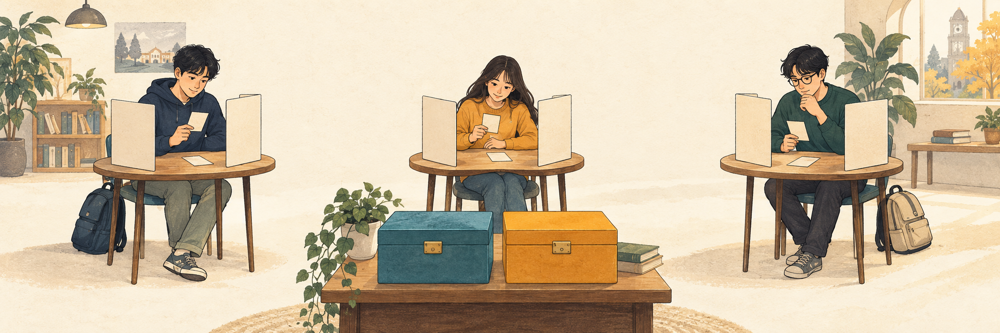

*입력 이후 참가자 간 통신 금지.*


In [ ]:
# 직접 작성 3-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def build_ghz3():
    "000에서 GHZ+를 만드는 3-qubit 회로. 측정은 넣지 마세요."
    qc = QuantumCircuit(3)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("build_ghz3")
    # TODO END
    return qc


In [ ]:
# 직접 작성 3-2 — TODO BEGIN과 TODO END 사이만 작성하세요.
def local_basis(party, input_bit):
    "자신의 party·입력만 사용하는 1-qubit basis 변환"
    qc = QuantumCircuit(1)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("local_basis")
    # TODO END
    return qc


In [ ]:
#@title 실행 3-2 — GHZ 준비와 로컬 측정 확인
def inspect_strategy():
    resource = validate_fragment(build_ghz3(), 3)
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("GHZ preparation fidelity:", state_fidelity(Statevector(resource), target))
    strategy = freeze_strategy(local_basis)
    display(resource.draw("mpl"))
    for party in PARTIES:
        for bit in (0, 1):
            print(f"{party} input: {bit}")
            display(strategy[party, bit].draw("mpl"))
    display(build_mermin_round(resource, strategy, (0, 1, 1)).draw("mpl", fold=100))

run_if_ready(inspect_strategy)

**실험 메모 3-2 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 3-3. 승률과 Mermin 값 · 7점

`mermin_report()`에서는 네 입력 각각에 대한 상관값(correlator) $E_{xyz}=\langle(-1)^{a+b+c}\rangle$와 승률을 **정확한 확률로 계산하여 반환**하세요. 아래 제공 실험은 입력마다 4096회 측정한 표본 결과와 정확한 계산 결과를 함께 출력합니다. 두 결과를 비교하세요.

$$M_{game}=E_{000}-E_{011}-E_{101}-E_{110}.$$

아래 TODO 코드 셀에서 `mermin_report()`를 작성합니다. **3-2에서 작성한 GHZ 준비 회로와 여섯 측정 전 기저 변환 회로**를 사용하세요.

**반환 형식:** `(E, win_rates, M, p_win)`

- `E`: 입력 `000, 011, 101, 110` 순서의 정확한 상관값 4개.
- `win_rates`: 같은 입력 순서의 정확한 승률 4개.
- `M`: 위 식으로 계산한 Mermin 게임 값.
- `p_win`: 네 입력을 균등하게 평균한 승률.

`E`와 `win_rates`는 각각 길이 4의 tuple로 반환합니다. 확률 계산은 자유롭게 구현할 수 있으며, 공개된 정확 계산 도구를 활용해도 됩니다.

**채점 사항:** 네 입력의 수치 결과와 전체 M·승률. 이 수치 항목은 **3-2의 GHZ+ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다. 실험 메모에는 $p_{win}=1/2+M_{game}/8$을 유도하고 고전 기준과 비교하세요.

| 평균 승률 | M 값 | 의미 |
|---|---:|---|
| 75% | 2 | 가장 좋은 고전 전략의 평균 성능 |
| 75% 초과 | 2 초과 | 공유 난수와 사전 합의만으로 가능한 평균 성능을 넘어섬 |
| 100% | 4 | 모든 허용 입력에서 공동 조건을 만족함 |

표의 고전 상한 75%는 네 입력이 같은 확률로 주어질 때의 이론적 평균 승률에 적용됩니다. 유한한 횟수로 실험해 얻은 승률은 표본 변동 때문에 75%를 넘을 수도 있습니다.

아래 「실행 3-3 — 네 입력의 승률·M 확인」 셀은 직접 준비한 GHZ의 정확한 계산 결과·표본 결과와, **2번에서 전송한 GHZ의 표본 결과**를 함께 보여 줍니다. 2번이 미완성이어도 직접 준비한 GHZ 시험은 진행할 수 있습니다. `mermin_report()`의 계산 대상은 직접 준비한 3-2의 자원입니다.

이 실행 셀은 비교용 결과를 별도로 계산하며 **`mermin_report()`를 호출하지 않습니다.** 따라서 실험 결과가 출력되어도 해당 TODO 함수의 완성 여부나 반환값이 검증된 것은 아닙니다. 이 함수의 반환값은 마지막 채점 셀에서 검사합니다.


In [ ]:
# 직접 작성 3-3 — TODO BEGIN과 TODO END 사이만 작성하세요.
def mermin_report():
    E = win_rates = M = p_win = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("mermin_report")
    # TODO END
    return E, win_rates, M, p_win


In [ ]:
#@title 실행 3-3 — 네 입력의 승률·M 확인
def inspect_game():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    sampled = sample_game(resource, strategy)
    exact = exact_game(resource, strategy)
    print("4096 shots / input")
    show_game(sampled)
    print("exact probabilities")
    show_game(exact)
    return sampled, exact

game_results = run_if_ready(inspect_game)

def inspect_linked_game():
    strategy = freeze_strategy(local_basis)
    report = sample_linked_game(strategy)
    print("Q-LINK: 2번에서 전송한 GHZ의 공동 시험 (4096 shots / input)")
    show_game(report)
    return report

linked_game_result = run_if_ready(inspect_linked_game)

**실험 메모 3-3 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 3-4. 공유 자원 교체 · 6점

1-6에서 이론적인 Z 측정 분포가 같았던 두 자원이 같은 협력 시험에서도 같은 성능을 낼까요? 3-2의 측정 전략을 유지한 채, GHZ 대신 000/111을 각각 확률 1/2로 준비하는 `coin_resource()`를 사용하세요. q3는 접근할 수 없는 기록계입니다.

아래 TODO 코드 셀에서 `resource_comparison()`을 작성합니다.

**반환 형식:** `(ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best)`

앞의 네 값은 3-2의 같은 로컬 측정 전략을 각각 GHZ와 동전 자원에 적용한 정확한 M·평균 승률입니다. GHZ는 `build_ghz3()`로 준비합니다. 마지막 값 `classical_best`는 **3-1에서처럼 각자가 자신의 입력 0/1에 대해 출력 bit를 정하는 고전 전략 전체의 최대 평균 승률**입니다. 측정 결과를 사용하지 않고 출력 bit를 정하는 전략도 허용합니다. 이 값은 3-1의 전략 탐색 결과를 활용해도 됩니다.

**채점 사항:** 두 자원의 정확한 수치 비교와 고전 전략 전체의 최대 평균 승률. 앞의 네 비교값은 **3-2의 GHZ+ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다. `classical_best`는 이 조건과 독립적으로 채점하며, 동전 자원에 3-2의 측정 전략을 적용한 승률과 구분하세요.

아래 「실행 3-4 — 동전 자원 실험」과 「실행 3-4 — 두 자원 비교 — 승률 그림」 셀은 회로에서 비교용 결과를 별도로 계산하며 **`resource_comparison()`을 호출하지 않습니다.** 이 함수의 완성 여부와 반환값은 마지막 채점 셀에서 검사합니다.

실험 메모에는 두 자원의 Z 기저 측정 분포가 같은데도, 3-2의 측정 전략을 적용했을 때 상관값과 승률이 달라지는 이유를 적으세요.


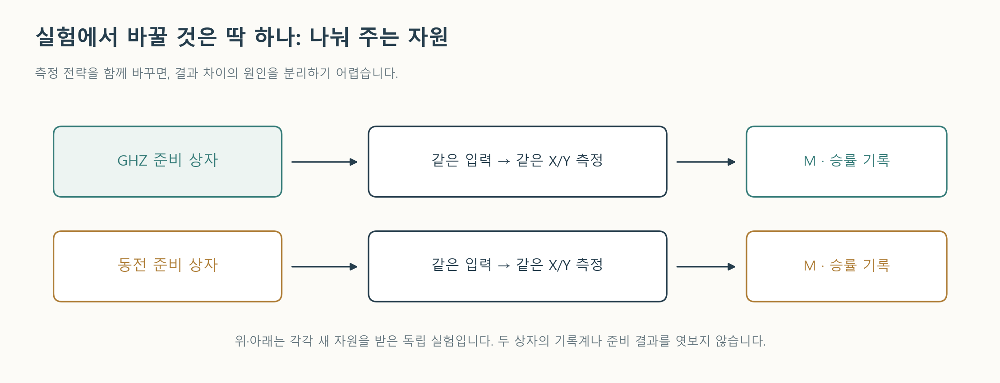

*같은 전략에서 공유 자원만 교체합니다.*


In [ ]:
# 직접 작성 3-4 — TODO BEGIN과 TODO END 사이만 작성하세요.
def resource_comparison():
    ghz_M = ghz_p_win = coin_M = coin_p_win = classical_best = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("resource_comparison")
    # TODO END
    return ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best


In [ ]:
#@title 실행 3-4 — 동전 자원 실험
def inspect_coin():
    strategy = freeze_strategy(local_basis)
    resource = coin_resource()
    rho = partial_trace(Statevector(resource), [3])
    print("coin reduced-state purity:", rho.purity().real)
    print("sampled coin strategy")
    show_game(sample_game(resource, strategy))
    print("exact coin strategy")
    show_game(exact_game(resource, strategy))

run_if_ready(inspect_coin)

*왼쪽은 입력별 승률, 오른쪽은 네 입력을 균등하게 평균한 승률입니다. 75% 고전 상한은 오른쪽 평균에 적용됩니다. 동전 막대는 X/Y 전략을 유지한 결과이며, 최선의 고전 출력 전략과 구분하세요.*


In [ ]:
#@title 실행 3-4 — 두 자원 비교 — 승률 그림
def compare_game_resources():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    quantum = sample_game(resource, strategy)
    coin = sample_game(coin_resource(), strategy)
    plot_game_comparison(quantum, coin)

run_if_ready(compare_game_resources)

**실험 메모 3-4 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


<a id="optional"></a>

# 선택 심화 · 추가 20점

기본 문항 100점과 별도로 2-5는 **추가 12점**, 3-5는 **추가 8점**입니다. 2-5는 2-2, 3-5는 3-2를 완성한 뒤 진행합니다. 원하는 문항만 제출할 수 있으며, 미제출 선택 문항은 기본 점수를 깎지 않습니다.


## 2-5. 선택 · 두 qubit의 상관관계까지 전송 · 추가 12점

**먼저 아래 「실행 2-5 — 결함 재현 — 오류 메시지에서 출발」 셀을 실행하고 자원 연결·보정 대상의 두 결함을 찾으세요.** 각 전송 경로의 공유 자원은 2-2와 같은 $|\Phi^+\rangle$ Bell pair로 준비합니다. 두 쌍의 자원과 고전 bit 4개를 사용하여 입력 두 qubit의 전체 상태를 전송하세요.

- 전체 회로에서 `q0, q1, q2, q3, q4, q5`는 각각 `Q0, Q1, A0, A1, B0, B1`입니다.
- 측정 결과는 `Q0→c0`, `A0→c1`, `Q1→c2`, `A1→c3`에 저장합니다.
- `shared_pairs_2q()`는 로컬 `[A0, A1, B0, B1]` 순서의 측정 없는 `QuantumCircuit(4)`를 반환합니다.
- `bob_decoder_2q()`는 로컬 `[B0, B1]` 순서의 `QuantumCircuit(2, 4)`를 반환합니다. H/X/Z와 `if_test`만 사용하며, 출력 순서는 고정합니다. `if_test`에는 2-2와 같이 이 회로의 고전 비트 하나를 0 또는 1과 비교하는 조건만 사용하세요. 여러 비트의 조건을 함께 확인하려면 단일 비트 조건문을 중첩합니다.

2-2에서 작성한 `alice_encoder()`를 재사용해 수정본을 검증하세요. 발견한 두 결함과 수정 이유를 실험 메모에 적으세요. 또한 Bell 상태와 Haar 무작위 상태를 입력했을 때의 두 qubit 전체 상태의 fidelity를 기록하고, 각 qubit의 축약 상태(reduced state)를 따로 검사하는 것만으로는 전송 성공을 확인하기에 부족한 이유를 설명하세요.

**채점 사항:** 올바른 두 Bell 자원과 두 qubit 전체 상태의 전송. 모든 16개 측정 분기를 검사하며, 얽힌 입력의 상관관계와 출력 순서까지 보존해야 합니다.


In [ ]:
with _qff_experiment("제공 실험 78"):
    #@title 실행 2-5 — 결함 재현 — 오류 메시지에서 출발
    bad_pair4 = QuantumCircuit(4)
    bad_pair4.h(0)
    bad_pair4.cx(0, 1)
    bad_pair4.h(2)
    bad_pair4.cx(2, 3)
    bad_bob2 = QuantumCircuit(2, 4)
    with bad_bob2.if_test((bad_bob2.clbits[0], 1)):
        bad_bob2.z(1)
    with bad_bob2.if_test((bad_bob2.clbits[1], 1)):
        bad_bob2.x(1)
    with bad_bob2.if_test((bad_bob2.clbits[2], 1)):
        bad_bob2.z(0)
    with bad_bob2.if_test((bad_bob2.clbits[3], 1)):
        bad_bob2.x(0)
    _, alice_for_debug, _ = broken_parts()
    broken2 = protocol_2q(bad_pair4, alice_for_debug, bad_bob2)
    debug_report_2_5 = sample_fidelity(broken2, haar_prep(0, 2), (0, 1), (4, 5))
    debug_passed_2_5 = report_transfer_check(debug_report_2_5, "2-qubit Haar seed=0", "2-5")
    display(broken2.draw("mpl", fold=100, cregbundle=False))
    show_fidelity(debug_report_2_5)


In [ ]:
# 직접 작성 2-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def shared_pairs_2q():
    "A0,A1,B0,B1 순서, 4-qubit 자원 회로"
    qc = QuantumCircuit(4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("shared_pairs_2q")
    # TODO END
    return qc


In [ ]:
# 직접 작성 2-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def bob_decoder_2q():
    "B0,B1 순서, 2-qubit 4-cbit 조건부 보정 회로"
    qc = QuantumCircuit(2, 4)
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("bob_decoder_2q")
    # TODO END
    return qc


In [ ]:
#@title 실행 2-5 — 복구 확인 — joint fidelity
def inspect_two():
    protocol = protocol_2q(shared_pairs_2q(), alice_encoder(), bob_decoder_2q())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    bell_payload = QuantumCircuit(2)
    bell_payload.h(0)
    bell_payload.cx(0, 1)
    print("Bell payload:")
    show_fidelity(sample_fidelity(protocol, bell_payload, (0, 1), (4, 5)))
    return public_teleport_check(protocol, n=2)

two_qubit_results = run_if_ready(inspect_two)

**실험 메모 2-5 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


## 3-5. 선택 · 위상 오류가 생겨도 고전 기준을 넘는가? · 추가 8점

GHZ 배분 전 Alice의 qubit에 확률 $p$로 Z 오류가 발생합니다. 오류 여부는 공개하지 않으며, 3-2에서 작성한 X/Y 측정 전략은 고정합니다.

$$\rho(p)=(1-p)|GHZ^+\rangle\langle GHZ^+|+p|GHZ^-\rangle\langle GHZ^-|.$$

아래 선택 TODO에서 `phase_noise_metrics()`의 계산을 작성하세요. 반환 tuple의 네 원소는 아래에 지정한 네 오류 확률의 계산 결과이며, 이 순서를 유지하세요.

**반환 형식:** $p=0,\ 0.1,\ 0.25,\ 0.5$ 순서로 `(M, p_win)` 쌍 4개를 담은 tuple입니다. 바깥 tuple의 길이는 4, 각 안쪽 tuple의 길이는 2입니다. `p_win`은 네 허용 입력을 균등하게 평균한 승률입니다.

GHZ+와 GHZ−에 동일한 측정 전략을 적용하여, 각 상태에서의 확률 또는 상관값을 계산하세요. **GHZ+의 결과에는 $(1-p)$, GHZ−의 결과에는 $p$를 곱해 더하세요.** 상태벡터의 진폭을 가중해 합치는 것은 이 혼합 상태와 다릅니다. 반환값에는 정확한 확률을 사용하고, 별도 표본 실험은 비교용으로 남깁니다.

**채점 사항:** 지정된 네 $p$에서의 M·승률 8개 값. 이 수치 항목은 **3-2의 GHZ+ 준비와 측정 전략이 요구 조건을 만족하는 경우에 채점**합니다. $p$에 대한 식과 고전 평균 승률 3/4를 넘는 범위는 실험 메모에 정리하세요. 별도의 계수·참/거짓 답안은 제출하지 않습니다.


In [ ]:
# 직접 작성 3-5 — TODO BEGIN과 TODO END 사이만 작성하세요.
def phase_noise_metrics():
    result_p0 = result_p01 = result_p025 = result_p05 = None
    # TODO BEGIN — 아래 raise를 지우고 필요한 계산/연산을 작성하세요.
    raise NotImplementedError("phase_noise_metrics")
    # TODO END
    return result_p0, result_p01, result_p025, result_p05


**실험 메모 3-5 · 채점 제외**

작성한 회로와 계산 과정, 실험 결과를 비교한 내용과 그 근거를 자유롭게 적으세요.

…


<a id="finish"></a>

# 개통 보고서·제출

**팀명 / 참가자:** …

아래 세 줄은 기존 실험 메모를 요약하면 됩니다. 보고서와 설명문은 채점 대상이 아닙니다.

| 개통 시험 | 결과와 근거 |
|---|---|
| 측정·자원 점검 | 같은 이론적 Z 측정 분포를 갖는 상태를 구별한 측정과 결과: … |
| 전송 복구 | 평균·최소 fidelity와 보정이 필요한 이유: … |
| 세 실험실 협력 | GHZ·동전 승률, M, 고전 기준과의 차이: … |

**배점**

| 문항 | 점수 | 문항 | 점수 | 문항 | 점수 |
|---|---:|---|---:|---|---:|
| 1-1 | 3 | 2-1 | 6 | 3-1 | 7 |
| 1-2 | 3 | 2-2 | 18 | 3-2 | 10 |
| 1-3 | 4 | 2-3 | 7 | 3-3 | 7 |
| 1-4 | 5 | 2-4 | 9 | 3-4 | 6 |
| 1-5 | 7 |  |  |  |  |
| 1-6 | 8 |  |  |  |  |
| **1번 합계** | **30** | **2번 합계** | **40** | **3번 합계** | **30** |

기본 점수는 **100점**입니다. 선택 2-5는 **추가 12점**, 선택 3-5는 **추가 8점**으로 별도 표시합니다.

**채점 및 제출 방법**

아래 최종 셀은 수정하지 마세요. 현재 실행에서 작성한 함수의 반환값을 한 번 수집하고, **같은 제출 묶음으로 채점·저장**합니다. 기본·추가 점수와 미완성·오류 항목을 확인하세요. 미작성 선택 문제는 기본 점수를 깎지 않습니다.

실행별 폴더에 제출 JSON, 점수 JSON, 실행 정보와 제출 ZIP이 저장됩니다. Colab은 마지막에 ZIP 다운로드를 요청합니다. 브라우저에서 다운로드가 차단되면 셀에서 출력된 링크·경로를 이용하세요. 최신 점수 표시와 함께 실행 ID를 확인하고, **해당 제출 ZIP과 작성한 노트북**을 제출합니다. 노트북은 Colab 메뉴에서 `.ipynb`로 다운로드하세요.

수정한 뒤 모두 실행하면 새 실행 ID로 다시 저장합니다. 이전 제출은 덮어쓰지 않습니다. 2-1·2-5의 원본 실패 메시지는 의도된 디버깅 결과이며, 수정한 전송 회로의 검증은 통과해야 합니다.


In [ ]:
#@title 최종 자동 채점·제출 파일 저장 — 수정하지 마세요
# 현재 실행에서 정의한 함수만 수집합니다. 미작성 선택 문제는 자동으로 제외합니다.
# 같은 수집 결과를 채점하고 제출 JSON·점수표·ZIP에 저장합니다.
_qff_final_result = finalize_submission(globals())


**참고 자료**

- [IBM: Quantum teleportation](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation)
- [Qiskit 비트 순서](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering) · [조건부 연산](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)
- [Quantum Pseudo-Telepathy](https://arxiv.org/abs/quant-ph/0407221)
- [GHZ 게임의 고전 상한과 양자 전략](https://arxiv.org/abs/quant-ph/0408090)
